# Assignment: Explainable AI for Time Series Forecasting

**Dataset:** Beijing PM2.5 air quality, 2010–2014 (Liang et al., 2015, UCI Machine Learning Repository)

**Name:** Vineetha N **USN:** 1RUB25CSE0019

In this assignment you build next-day air-pollution forecasters for Beijing and explain them with permutation importance, SHAP, LIME and attribution methods. The lecture notebook used a univariate temperature series. This dataset adds real weather drivers, so you must explain *exogenous* inputs, not just lags.

### Instructions
- Rename this file `XAI_TS_<RollNo>.ipynb` and submit it run top to bottom, with all outputs visible.
- Every `# TODO` cell must be completed. Answer each question in the **Your answer** cell below its code.
- Written answers: 3–6 sentences each, quoting the numbers your code produced.
- Use only data up to day *t − 1* to forecast day *t*, unless a question explicitly says otherwise. Leakage costs marks in every part it affects.
- Keep `SEED = 42` for NumPy, PyTorch, LightGBM and LIME.
- You may reuse functions from the lecture notebook, but you must adapt them.
- The notebook must run on a CPU in under 20 minutes.

### Marks
| Part | Topic | Marks |
|---|---|---|
| A | Exploration and a sanity prior | 10 |
| B | Feature engineering and forecasters | 15 |
| C | SHAP | 25 |
| D | LIME | 15 |
| E | Sequence model and attribution methods | 15 |
| F | Evaluating explanations | 10 |
| G | Reflection | 10 |
| Bonus | Extensions | +10 |
| | **Total** | **100** |

## 0. Setup
Uncomment the install line if any library is missing.

In [1]:
# !pip install shap lime lightgbm statsmodels torch scikit-learn pandas matplotlib seaborn scipy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer

import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("shap", shap.__version__, "| lightgbm", lgb.__version__, "| torch", torch.__version__)

shap 0.52.0 | lightgbm 4.7.0 | torch 2.11.0+cpu


## Dataset

Hourly PM2.5 concentration at the US Embassy in Beijing, with weather from Beijing Capital Airport: 43,824 hours. You will aggregate to **daily** values (1,826 days) and forecast **tomorrow's mean PM2.5 (µg/m³)**.

| Column | Meaning | Daily aggregation |
|---|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³), **target** | mean |
| `DEWP` | Dew point (°C), a humidity proxy | mean |
| `TEMP` | Temperature (°C) | mean |
| `PRES` | Air pressure (hPa) | mean |
| `cbwd` | Combined wind direction: NW, NE, SE, cv (calm/variable) | most frequent |
| `Iws` | Cumulated wind speed (m/s) | max |
| `Is` | Cumulated hours of snow | max |
| `Ir` | Cumulated hours of rain | max |

**Chronological split (fixed for everyone):** train 2010–2012, validation 2013 (early stopping only), test 2014. Compute every explanation on the 2014 test year.

**Domain hints.** Beijing pollution builds up over several stagnant, humid days and is flushed out by strong, dry north-westerly winds. Winter heating raises baseline levels. These are your *sanity prior*.

The starter code below is provided; run it as given.

In [2]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
raw = pd.read_csv(URL)
raw["date"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw = raw.set_index("date").drop(columns=["No", "year", "month", "day", "hour"])

daily = raw.resample("D").agg({
    "pm2.5": "mean", "DEWP": "mean", "TEMP": "mean", "PRES": "mean",
    "Iws": "max", "Is": "max", "Ir": "max",
    "cbwd": lambda s: s.mode().iloc[0] if len(s.mode()) else np.nan,
})
print(daily.shape, "|", daily["pm2.5"].isna().sum(), "days without PM2.5")
daily.head()

(1826, 8) | 37 days without PM2.5


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd
date,,,,,,,,
2010-01-01,NaN,-18.750000,-6.750000,1017.083333,43.82,0,0,NW
2010-01-02,145.958333,-8.500000,-5.125000,1024.750000,55.43,4,0,SE
2010-01-03,78.833333,-10.125000,-8.541667,1022.791667,127.84,27,0,SE
2010-01-04,31.333333,-20.875000,-11.500000,1029.291667,198.45,0,0,NW
2010-01-05,42.458333,-24.583333,-14.458333,1033.625000,218.57,0,0,NW


In [3]:
def metrics(y_true, y_pred):
    """MAE and RMSE. Always call this with values in µg/m³."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

---
# Part A: Exploration and a sanity prior (10 marks)
Build the prior that your explanations will be checked against later.

### A1 (2 marks)
Handle the 37 days with no PM2.5 reading. Write code that compares two strategies, **linear interpolation** and **forward fill**, and justify the one you keep. Explain why you must never fill gaps using values from the future *when building features*.

37 missing days in 19 gaps | longest gap = 5 days
gap lengths (days): [5, 4, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1]
other columns, missing values: {'DEWP': 0, 'TEMP': 0, 'PRES': 0, 'Iws': 0, 'Is': 0, 'Ir': 0, 'cbwd': 0}


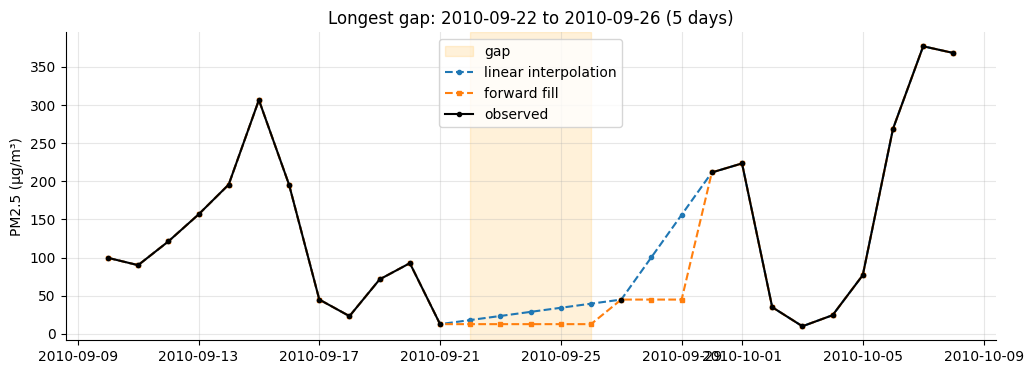


Simulated 3-day gaps (300 trials):


,MAE (µg/m³),std. error
linear interpolation,52.98,2.02
forward fill,69.41,2.95


Summary statistics:


,count,mean,std,skew
observed only,1789.0,98.65,77.55,1.62
interpolated,1825.0,98.53,77.11,1.62
forward-filled,1825.0,98.06,77.23,1.62


NaN left in daily_clean: {'pm2.5': 1} (leading days, before the first reading)


In [4]:
pm_raw = daily["pm2.5"]
missing = pm_raw.isna()
run_id = (missing != missing.shift()).cumsum()
gap_len = missing.groupby(run_id).sum()
gap_len = gap_len[gap_len > 0].astype(int)
print(f"{missing.sum()} missing days in {len(gap_len)} gaps | longest gap = {gap_len.max()} days")
print("gap lengths (days):", sorted(gap_len.tolist(), reverse=True))
print("other columns, missing values:", daily.drop(columns="pm2.5").isna().sum().to_dict())

pm_interp = pm_raw.interpolate(method="linear", limit_area="inside")   # needs the value AFTER the gap
pm_ffill = pm_raw.ffill()                                              # needs only the past

# --- look at the longest gap
longest = gap_len.idxmax()
gap_days = pm_raw.index[run_id == longest]
lo, hi = gap_days[0] - pd.Timedelta(days=12), gap_days[-1] + pd.Timedelta(days=12)
fig, ax = plt.subplots()
ax.axvspan(gap_days[0], gap_days[-1], color="orange", alpha=0.15, label="gap")
ax.plot(pm_interp[lo:hi], "--o", ms=3, label="linear interpolation")
ax.plot(pm_ffill[lo:hi], "--s", ms=3, label="forward fill")
ax.plot(pm_raw[lo:hi], "k.-", label="observed")
ax.set_title(f"Longest gap: {gap_days[0].date()} to {gap_days[-1].date()} ({len(gap_days)} days)")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(); plt.show()

# --- simulated gaps: hide 3 known days, fill them, measure the error
rng = np.random.default_rng(SEED)
obs, vals, L = pm_raw.notna().values, pm_raw.values, 3
cand = [s for s in range(1, len(pm_raw) - L - 1) if obs[s - 1:s + L + 1].all()]
errs = {"linear interpolation": [], "forward fill": []}
for s in rng.choice(cand, 300, replace=False):
    tmp = pm_raw.copy(); tmp.iloc[s:s + L] = np.nan
    errs["linear interpolation"].append(np.abs(tmp.interpolate(limit_area="inside").values[s:s + L] - vals[s:s + L]).mean())
    errs["forward fill"].append(np.abs(tmp.ffill().values[s:s + L] - vals[s:s + L]).mean())
sim = pd.DataFrame({k: [np.mean(v), np.std(v) / np.sqrt(len(v))] for k, v in errs.items()}, index=["MAE (µg/m³)", "std. error"]).T
print("\nSimulated 3-day gaps (300 trials):"); display(sim.round(2))

stats = pd.DataFrame({"observed only": pm_raw, "interpolated": pm_interp, "forward-filled": pm_ffill}).agg(["count", "mean", "std", "skew"]).T
print("Summary statistics:"); display(stats.round(2))

# --- cleaned data used from here on: forward fill is causal (uses only past values)
daily_clean = daily.copy()
daily_clean["pm2.5"] = pm_ffill
daily_clean = daily_clean.ffill()
print("NaN left in daily_clean:", daily_clean.isna().sum()[lambda s: s > 0].to_dict(), "(leading days, before the first reading)")

**A1 — Your answer:**

The 37 missing PM2.5 days form 19 gaps, the longest only 5 days, and every weather column is complete. In a simulation that hid 3 known days 300 times, linear interpolation was more accurate (MAE 52.98 ± 2.02 µg/m³) than forward fill (69.41 ± 2.95), and the overall statistics barely differ (mean 98.5 vs 98.1, skewness 1.62 for both). I still keep **forward fill**, because interpolation needs the first reading *after* the gap: the value stored for day t−1 (and so every lag and rolling feature) would then contain information from day t or later. That is leakage: the model would be handed a smoothed version of the outcome it is supposed to forecast, and offline scores would look better than anything achievable live. The price of the causal choice is small (37 of 1,826 days, about 2%, carry a stale value); one leading day before the first reading stays NaN and is dropped.

### A2 (2 marks)
Plot daily PM2.5 for 2010–2014 with a 30-day rolling mean. Then plot its histogram and that of `log1p(PM2.5)`. Report the skewness of both and decide whether to model the **raw** or the **log** target. State how this choice will change the *units* of every SHAP value you report later.

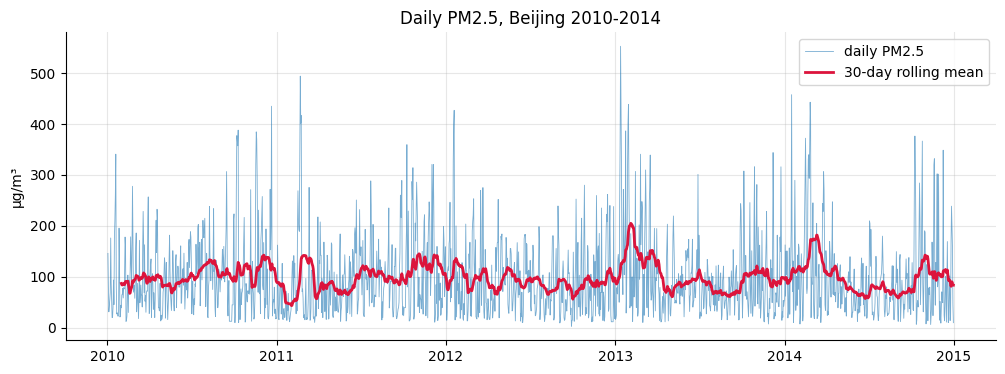

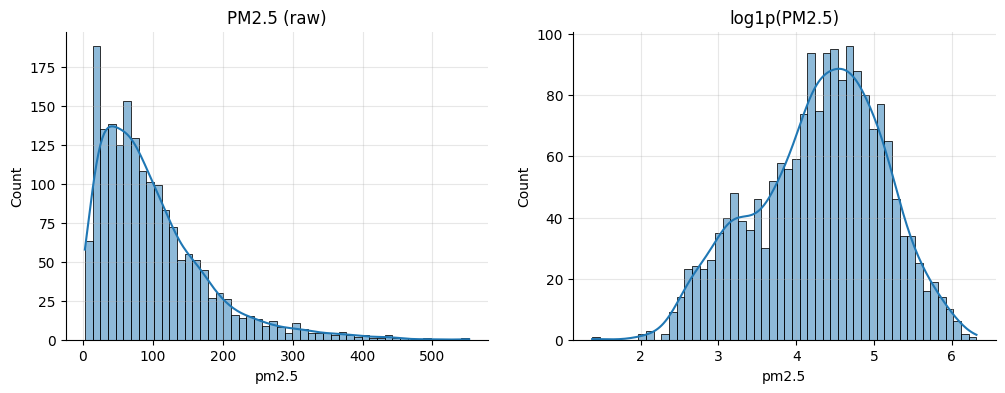

skewness raw = 1.62 | skewness log1p = -0.31
mean = 98.1, median = 78.9, max = 552 µg/m³


In [5]:
pm = daily_clean["pm2.5"].dropna()
fig, ax = plt.subplots()
ax.plot(pm, lw=0.6, alpha=0.6, label="daily PM2.5")
ax.plot(pm.rolling(30).mean(), color="crimson", lw=2, label="30-day rolling mean")
ax.set_ylabel("µg/m³"); ax.set_title("Daily PM2.5, Beijing 2010-2014"); ax.legend(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pm, bins=50, kde=True, ax=axes[0]); axes[0].set_title("PM2.5 (raw)")
sns.histplot(np.log1p(pm), bins=50, kde=True, ax=axes[1]); axes[1].set_title("log1p(PM2.5)")
plt.show()

skew_raw, skew_log = pm.skew(), np.log1p(pm).skew()
print(f"skewness raw = {skew_raw:.2f} | skewness log1p = {skew_log:.2f}")
print(f"mean = {pm.mean():.1f}, median = {pm.median():.1f}, max = {pm.max():.0f} µg/m³")

USE_LOG_TARGET = True   # decision: log1p cuts the skewness a lot (see above), so we model log1p(PM2.5)
assert abs(skew_log) < abs(skew_raw)
y_target = np.log1p(pm) if USE_LOG_TARGET else pm

**A2 — Your answer:**

Daily PM2.5 is strongly right-skewed (skewness 1.62; mean 98.1 vs median 78.9, maximum 552 µg/m³) with winter peaks visible in the 30-day rolling mean, while log1p(PM2.5) is almost symmetric (skewness −0.31). I therefore model the **log1p target** (`USE_LOG_TARGET = True`), which also makes errors relative, so a 20 µg/m³ miss on a clean day counts more than on a smog day. The consequence for explanations is that every SHAP value is in **log1p units** and additive on the log scale: φ = +0.1 multiplies the forecast by exp(0.1) ≈ 1.11 (about +11%), and the SHAP base value corresponds to a geometric-type mean, not an arithmetic one. Values must be converted with expm1 before they are read in µg/m³, and SHAP values cannot be added in µg/m³.

### A3 (3 marks)
Run an STL decomposition (period 365) on your chosen target. Report the share of variance in the seasonal and residual components. Compare with the temperature series from the lecture (66.9% seasonal): is pollution more or less predictable from the calendar alone? Explain why physically.

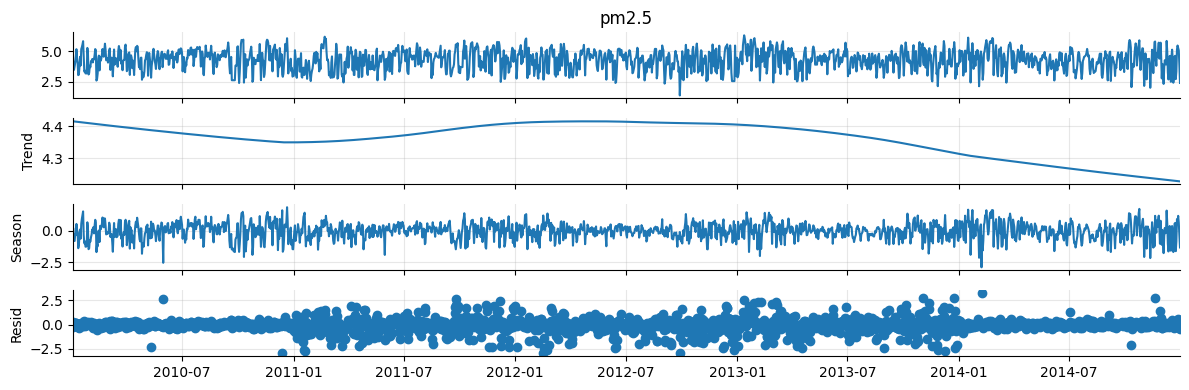

trend        0.4 %
seasonal    61.7 %
residual    73.0 %
dtype: object
sum of the three shares = 135.1% (not 100%: the components are correlated)
seasonal + trend = 62.3% of the variance
Lecture temperature series: 66.9% seasonal
calendar-only climatology (trained 2010-2012) on 2014: R2 = -0.037, i.e. the calendar explains about -4% of the variance of the 2014 target


In [6]:
stl = STL(y_target.asfreq("D"), period=365, robust=True).fit()
stl.plot(); plt.show()

tot = y_target.var()
shares = pd.Series({"trend": stl.trend.var() / tot, "seasonal": stl.seasonal.var() / tot, "residual": stl.resid.var() / tot})
print((shares * 100).round(1).astype(str) + " %")
print(f"sum of the three shares = {shares.sum()*100:.1f}% (not 100%: the components are correlated)")
print(f"seasonal + trend = {(stl.seasonal + stl.trend).var() / tot * 100:.1f}% of the variance")
print("Lecture temperature series: 66.9% seasonal")

# STL shares are in-sample (only 5 yearly cycles). Out-of-sample check: calendar-only 'climatology' forecast.
# mean target by day of year over 2010-2012 (+-15-day circular smoothing), evaluated on 2014
clim_src = y_target.loc[:"2012-12-31"]
by_doy = clim_src.groupby(clim_src.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
ext = pd.concat([by_doy.iloc[-15:], by_doy, by_doy.iloc[:15]]).rolling(31, center=True).mean().iloc[15:-15]
ext.index = range(1, 367)
t14 = y_target.loc["2014-01-01":]
clim_pred = ext.reindex(t14.index.dayofyear).values
r2_cal = 1 - np.sum((t14.values - clim_pred) ** 2) / np.sum((t14.values - t14.mean()) ** 2)
print(f"calendar-only climatology (trained 2010-2012) on 2014: R2 = {r2_cal:.3f}, i.e. the calendar explains about {r2_cal*100:.0f}% of the variance of the 2014 target")

**A3 — Your answer:**

On log1p(PM2.5) the STL decomposition (period 365, robust) gives trend 0.4%, seasonal 61.7% and residual 73.0% of the variance. The shares add up to 135% because the seasonal and residual parts are negatively correlated (seasonal + trend together carry 62.3%), a side effect of estimating each day-of-year profile from only five cycles. The seasonal share is a bit below the temperature series (66.9%) and the residual is large, so pollution is *less* predictable from the calendar alone. A calendar-only climatology fitted on 2010–2012 confirms it out of sample: R² = −0.04 on 2014. Physically, temperature follows the sun's fixed orbit, whereas PM2.5 depends on the weather: stagnant episodes build up over several days and are flushed out by cold fronts at irregular times, and winter heating only adds a modest baseline (111.1 vs 91.6 µg/m³ in heating vs other months).

### A4 (3 marks)
1. Plot the ACF and PACF of the target up to lag 30.
2. Compute the Spearman correlation between **tomorrow's** PM2.5 and **today's** value of each weather variable (`DEWP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`).
3. Show the mean next-day PM2.5 by today's wind direction (`cbwd`).

From these results, write down your **sanity prior**: a ranked list of the 4–5 inputs you expect a faithful explanation to put at the top, with the expected sign (+ / −) of each.

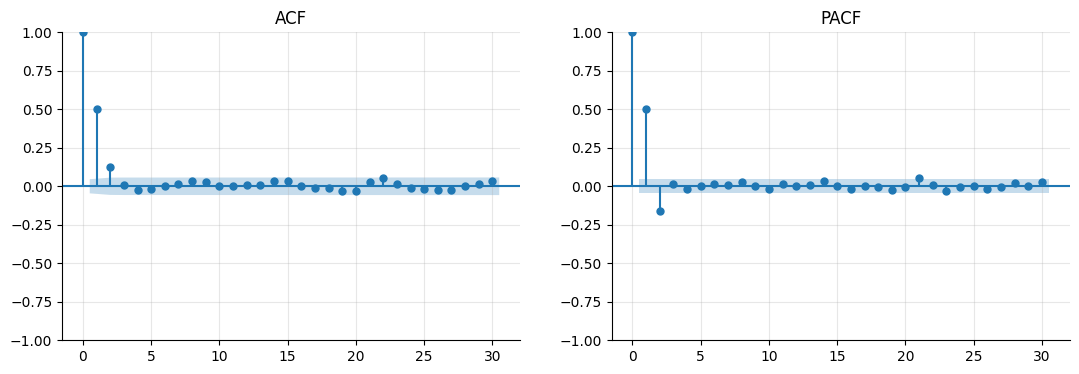

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(y_target, lags=30, ax=axes[0]); axes[0].set_title("ACF")
plot_pacf(y_target, lags=30, ax=axes[1], method="ywm"); axes[1].set_title("PACF")
plt.show()

,Spearman rho with next-day PM2.5
PM2.5 (today),0.498
Iws,-0.369
Ir,-0.129
DEWP,0.109
Is,0.035
PRES,0.021
TEMP,-0.001


,mean,median,count
cbwd,,,
NE,70.9,53.5,95
NW,73.4,49.5,711
SE,109.3,97.9,801
cv,149.0,121.2,218


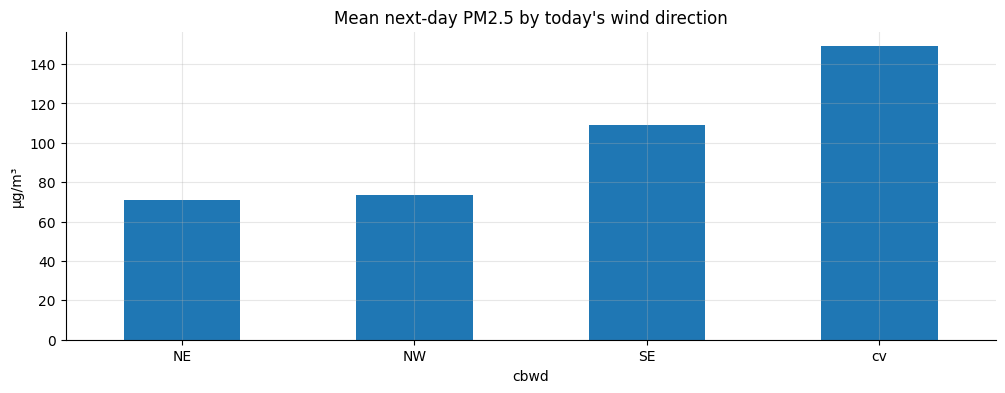

mean PM2.5, heating season (15 Nov-15 Mar): 111.1 | other months: 91.6


In [8]:
nxt = daily_clean["pm2.5"].shift(-1).rename("next-day PM2.5")   # tomorrow's value, aligned to today
cors = {}
for c in ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]:
    m = pd.concat([daily_clean[c], nxt], axis=1).dropna()
    cors["PM2.5 (today)" if c == "pm2.5" else c] = spearmanr(m.iloc[:, 0], m.iloc[:, 1])[0]
cors = pd.Series(cors, name="Spearman rho with next-day PM2.5").sort_values(key=np.abs, ascending=False)
display(cors.round(3).to_frame())

by_wind = pd.concat([daily_clean["cbwd"], nxt], axis=1).dropna().groupby("cbwd")["next-day PM2.5"].agg(["mean", "median", "count"]).sort_values("mean")
display(by_wind.round(1))
by_wind["mean"].plot.bar(title="Mean next-day PM2.5 by today's wind direction", ylabel="µg/m³", rot=0); plt.show()

md = daily_clean.index.month * 100 + daily_clean.index.day
heat = pd.Series((md >= 1115) | (md <= 315), index=daily_clean.index)
print("mean PM2.5, heating season (15 Nov-15 Mar): %.1f | other months: %.1f" % (daily_clean.loc[heat, "pm2.5"].mean(), daily_clean.loc[~heat, "pm2.5"].mean()))

**A4 — Your sanity prior:**

| Rank | Input | Expected sign | Reason |
|---|---|---|---|
| 1 | `pm_lag_1` (yesterday's PM2.5) | + | Strongest persistence: Spearman ρ = +0.50 with tomorrow's PM2.5; ACF and PACF are 0.50 at lag 1. |
| 2 | `Iws_lag_1` (cumulated wind speed) | − | Strong wind flushes pollution out: ρ = −0.37, the strongest weather correlation. |
| 3 | Wind direction: `wind_cv` / `wind_SE` (+), `wind_NW` / `wind_NE` (−) | + for calm or SE, − for NW | Mean next-day PM2.5 after calm (cv) 149.0, SE 109.3, NW 73.4 and NE 70.9 µg/m³. |
| 4 | `Ir_lag_1` (hours of rain) | − | Rain scavenges particles: ρ = −0.13. |
| 5 | `DEWP_lag_1` (humidity), also heating season | + | Humid, stagnant air traps pollution: ρ = +0.11; heating-season mean 111.1 vs 91.6 µg/m³. |

Evidence behind the ranking: the ACF is 0.50 at lag 1 and 0.12 at lag 2 and then stays inside the confidence band, and the PACF is 0.50 at lag 1 and −0.16 at lag 2 and nothing beyond. The series therefore has a memory of about two days, so I expect lag 1 (and a little of lag 2) to dominate and lags 4–7 to be close to irrelevant. TEMP and Is (|ρ| < 0.04) and PRES (ρ = 0.02) have almost no marginal signal.

---
# Part B: Feature engineering and forecasters (15 marks)

### B1 (5 marks)
Write `make_features(df) -> pd.DataFrame` that creates, for each day *t*, **only information available at the end of day t − 1**:

| Group | Features to create |
|---|---|
| PM2.5 recent lags | `pm_lag_1` … `pm_lag_3` |
| PM2.5 older lags | `pm_lag_4` … `pm_lag_7` |
| PM2.5 rolling stats | `pm_roll_mean_3`, `pm_roll_mean_7`, `pm_roll_std_7` |
| Weather, yesterday | `DEWP_lag_1`, `TEMP_lag_1`, `PRES_lag_1`, `Iws_lag_1`, `Is_lag_1`, `Ir_lag_1` |
| Weather change | `PRES_diff_1` (= PRES at t−1 minus t−2), `DEWP_diff_1` |
| Wind direction | one-hot of `cbwd` at t − 1 (4 columns) |
| Calendar | `doy_sin`, `doy_cos`, `is_heating_season` (15 Nov – 15 Mar), `dow` |

Store the groups in a dict `FEATURE_GROUPS`. Then write the leakage test: overwrite every raw value on one test day with random numbers, rebuild the features, and `assert` that the feature row for that same day is unchanged.

In [9]:
WINDS = ["NW", "NE", "SE", "cv"]

def make_features(df: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    pm = df["pm2.5"]
    # PM2.5 lags 1..7 (value at the end of day t-k)
    for k in range(1, 8):
        X[f"pm_lag_{k}"] = pm.shift(k)
    # rolling stats are computed on pm.shift(1), so they never touch day t
    pm1 = pm.shift(1)
    X["pm_roll_mean_3"] = pm1.rolling(3).mean()
    X["pm_roll_mean_7"] = pm1.rolling(7).mean()
    X["pm_roll_std_7"] = pm1.rolling(7).std()
    # yesterday's weather
    for c in ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]:
        X[f"{c}_lag_1"] = df[c].shift(1)
    # weather change between t-2 and t-1
    X["PRES_diff_1"] = df["PRES"].shift(1) - df["PRES"].shift(2)
    X["DEWP_diff_1"] = df["DEWP"].shift(1) - df["DEWP"].shift(2)
    # wind direction at t-1, one-hot
    wind1 = df["cbwd"].shift(1)
    for w in WINDS:
        X[f"wind_{w}"] = (wind1 == w).astype(float)
    # calendar: known in advance, so day t itself is fine
    doy = df.index.dayofyear
    X["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    X["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    md = df.index.month * 100 + df.index.day
    X["is_heating_season"] = ((md >= 1115) | (md <= 315)).astype(float)
    X["dow"] = df.index.dayofweek.astype(float)
    # target: day t (log1p if USE_LOG_TARGET)
    X["target"] = np.log1p(pm) if USE_LOG_TARGET else pm
    return X.dropna()

FEATURE_GROUPS = {
    "PM recent lags (1-3)": ["pm_lag_1", "pm_lag_2", "pm_lag_3"],
    "PM older lags (4-7)":  ["pm_lag_4", "pm_lag_5", "pm_lag_6", "pm_lag_7"],
    "PM rolling stats":     ["pm_roll_mean_3", "pm_roll_mean_7", "pm_roll_std_7"],
    "Weather yesterday":    ["DEWP_lag_1", "TEMP_lag_1", "PRES_lag_1", "Iws_lag_1", "Is_lag_1", "Ir_lag_1"],
    "Weather change":       ["PRES_diff_1", "DEWP_diff_1"],
    "Wind direction":       [f"wind_{w}" for w in WINDS],
    "Calendar":             ["doy_sin", "doy_cos", "is_heating_season", "dow"],
}

data = make_features(daily_clean)
feature_names = [c for c in data.columns if c != "target"]
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(feature_names), "FEATURE_GROUPS must partition the features"
print(f"{len(data)} samples x {len(feature_names)} features")

def to_ug(a):
    """Model-scale target -> µg/m³."""
    return np.expm1(a) if USE_LOG_TARGET else a

1818 samples x 26 features


In [10]:
# B1 leakage test: destroy every raw value on one test day; the features for that day must not change
test_day = pd.Timestamp("2014-06-15")
corrupted = daily_clean.copy()
rng = np.random.default_rng(SEED)
num_cols = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
corrupted.loc[test_day, num_cols] = rng.uniform(1000, 5000, len(num_cols))
corrupted.loc[test_day, "cbwd"] = "SE" if daily_clean.loc[test_day, "cbwd"] != "SE" else "NW"

feat_clean = make_features(daily_clean)
feat_corrupt = make_features(corrupted)
assert feat_corrupt.loc[test_day, "target"] != feat_clean.loc[test_day, "target"], "corruption must change the target"
assert feat_corrupt.loc[test_day, feature_names].equals(feat_clean.loc[test_day, feature_names])
# stronger: day t's raw values may only influence rows t+1 and later
assert feat_corrupt.loc[:test_day, feature_names].equals(feat_clean.loc[:test_day, feature_names])
print("Leakage test passed: target changed, features for", test_day.date(), "and all earlier days are identical")

Leakage test passed: target changed, features for 2014-06-15 and all earlier days are identical


### B2 (2 marks)
Apply the fixed split. Print the date range and number of rows of train, validation and test.

In [11]:
train = data.loc[:"2012-12-31"]
val = data.loc["2013-01-01":"2013-12-31"]
test = data.loc["2014-01-01":]
for name, d in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {d.index.min().date()} -> {d.index.max().date()} | {len(d):4d} rows")

X_train, y_train = train[feature_names], train["target"]
X_val, y_val = val[feature_names], val["target"]
X_test, y_test = test[feature_names], test["target"]
y_test_ug = to_ug(y_test)

train      2010-01-09 -> 2012-12-31 | 1088 rows
validation 2013-01-01 -> 2013-12-31 |  365 rows
test       2014-01-01 -> 2014-12-31 |  365 rows


### B3 (4 marks)
Fit and report test **MAE and RMSE in µg/m³** (even if you model the log target) for:
- (a) persistence: tomorrow = today,
- (b) 7-day mean,
- (c) a LightGBM regressor with early stopping on 2013.

Present the results in one table.

In [12]:
LGB_PARAMS = dict(n_estimators=2000, learning_rate=0.02, num_leaves=15, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbose=-1)
lgbm = lgb.LGBMRegressor(**LGB_PARAMS)
lgbm.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
print("best iteration:", lgbm.best_iteration_)
pred_lgbm_ug = to_ug(lgbm.predict(X_test))

results = pd.DataFrame({
    "Persistence": metrics(y_test_ug, X_test["pm_lag_1"]),
    "7-day mean":  metrics(y_test_ug, X_test["pm_roll_mean_7"]),
    "LightGBM":    metrics(y_test_ug, pred_lgbm_ug),
}).T.round(2)
results

best iteration: 125


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.10,67.16


**B3 — Your answer:**

On 2014, persistence reaches MAE 52.75 / RMSE 75.71 µg/m³, and the 7-day mean is worse (60.59 / 82.76) because the memory of the series is only about two days, as the ACF showed. LightGBM (stopped at 125 trees by the 2013 validation set) reaches MAE 45.10 / RMSE 67.16, which is 14.5% lower MAE and 11.3% lower RMSE than persistence. The gain is real but modest: an MAE of 45 µg/m³ is still about 46% of the 2014 mean (97.8 µg/m³), so next-day pollution is hard to forecast from yesterday's information alone. Every metric is computed in µg/m³ after expm1 of the log forecasts.

### B4 (4 marks) — the leakage experiment
Train a second LightGBM, `lgbm_oracle`, that additionally receives **day t's** weather (`DEWP`, `PRES`, `Iws`, `cbwd` at *t*). This simulates having a perfect weather forecast. Report its test MAE. In 3–4 sentences, explain when using such features is legitimate in a real system and when it is leakage. You will explain both models in Part C.

In [13]:
# oracle: also give the model day t's weather (a "perfect weather forecast")
ORACLE_FEATURES = ["DEWP_t", "PRES_t", "Iws_t"] + [f"wind_{w}_t" for w in WINDS]

def add_oracle(X):
    O = X.copy()
    today = daily_clean.loc[O.index]
    for c in ["DEWP", "PRES", "Iws"]:
        O[f"{c}_t"] = today[c].values
    for w in WINDS:
        O[f"wind_{w}_t"] = (today["cbwd"] == w).astype(float).values
    return O

X_train_o, X_val_o, X_test_o = add_oracle(X_train), add_oracle(X_val), add_oracle(X_test)
feature_names_o = list(X_train_o.columns)
FEATURE_GROUPS_O = {**FEATURE_GROUPS, "Weather today (oracle)": ORACLE_FEATURES}

lgbm_oracle = lgb.LGBMRegressor(**LGB_PARAMS)
lgbm_oracle.fit(X_train_o, y_train, eval_set=[(X_val_o, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
pred_oracle_ug = to_ug(lgbm_oracle.predict(X_test_o))
print("oracle best iteration:", lgbm_oracle.best_iteration_)
results.loc["LightGBM oracle (day-t weather)"] = pd.Series(metrics(y_test_ug, pred_oracle_ug)).round(2)
results

oracle best iteration: 497


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.10,67.16
LightGBM oracle (day-t weather),28.84,42.02


**B4 — Your answer:**

Giving the model the weather of day t itself lowers the test MAE from 45.10 to **28.84 µg/m³** (RMSE 67.16 → 42.02), a 36% improvement. Such features are legitimate when day-t weather is really available at forecast time, for example a numerical weather prediction issued before day t, and the model is trained on archived *forecasts* with their errors so that it sees the same noise in training and in deployment. It is leakage when observed day-t weather is used in training or evaluation but only forecasts (or nothing) exist when the real forecast is made: the score then measures a perfect weather forecast that nobody has. Here the oracle's improvement shows how much of the remaining error is simply the weather of the target day.

---
# Part C: SHAP (25 marks)
Use `shap.TreeExplainer` on the LightGBM from B3 unless told otherwise. If you model the log target, state clearly that SHAP values are in log units.

### C1 (3 marks)
Compute SHAP values for the 2014 test set. Verify the **efficiency** property numerically: report the maximum absolute gap between base value + Σφ and the model output. Report the base value and translate it into µg/m³.

In [14]:
tree_explainer = shap.TreeExplainer(lgbm)
shap_exp = tree_explainer(X_test)

model_out = lgbm.predict(X_test)                      # log1p units
recon = shap_exp.base_values + shap_exp.values.sum(axis=1)
gap = np.abs(recon - model_out)
base = float(np.ravel(shap_exp.base_values)[0])
print(f"max |base + sum(phi) - f(x)| = {gap.max():.2e}  (mean {gap.mean():.2e})")
print(f"base value = {base:.4f} (log1p units) -> {to_ug(base):.1f} µg/m³")
print(f"(the base value is the average of the model output on the background data, i.e. a geometric-type mean: expm1(mean(log1p y_train)) = {to_ug(y_train.mean()):.1f} µg/m³; the arithmetic mean of y_train is {to_ug(y_train).mean():.1f})")
print(f"mean test forecast = {to_ug(model_out).mean():.1f} µg/m³, actual test mean = {y_test_ug.mean():.1f} µg/m³")
assert gap.max() < 1e-4

max |base + sum(phi) - f(x)| = 1.11e-14  (mean 3.25e-15)
base value = 4.2855 (log1p units) -> 71.6 µg/m³
(the base value is the average of the model output on the background data, i.e. a geometric-type mean: expm1(mean(log1p y_train)) = 71.6 µg/m³; the arithmetic mean of y_train is 97.0)
mean test forecast = 82.5 µg/m³, actual test mean = 97.8 µg/m³


**C1 — Your answer:**

Efficiency holds numerically: the maximum absolute gap between base value + Σφ and the LightGBM output over the 365 test days is 1.1 × 10⁻¹⁴. All SHAP values are in **log1p units**. The base value is 4.2855, which is **71.6 µg/m³** after expm1; this is a geometric-type average (the arithmetic training mean is 97.0 µg/m³), so on log scale the explanation starts from a "typical" day below the arithmetic mean. The mean 2014 forecast is 82.5 µg/m³ against an actual mean of 97.8, because exponentiating a log-scale prediction gives roughly a median rather than a mean.

### C2 (5 marks)
Produce the global **bar** plot and **beeswarm** plot. Compare the top five features with your sanity prior from A4. For each weather feature in the top ten, state whether its colour pattern (direction) matches the physics in the domain hints. Identify one feature whose effect is *conditional*, like `lag_2` in the lecture, and explain it.

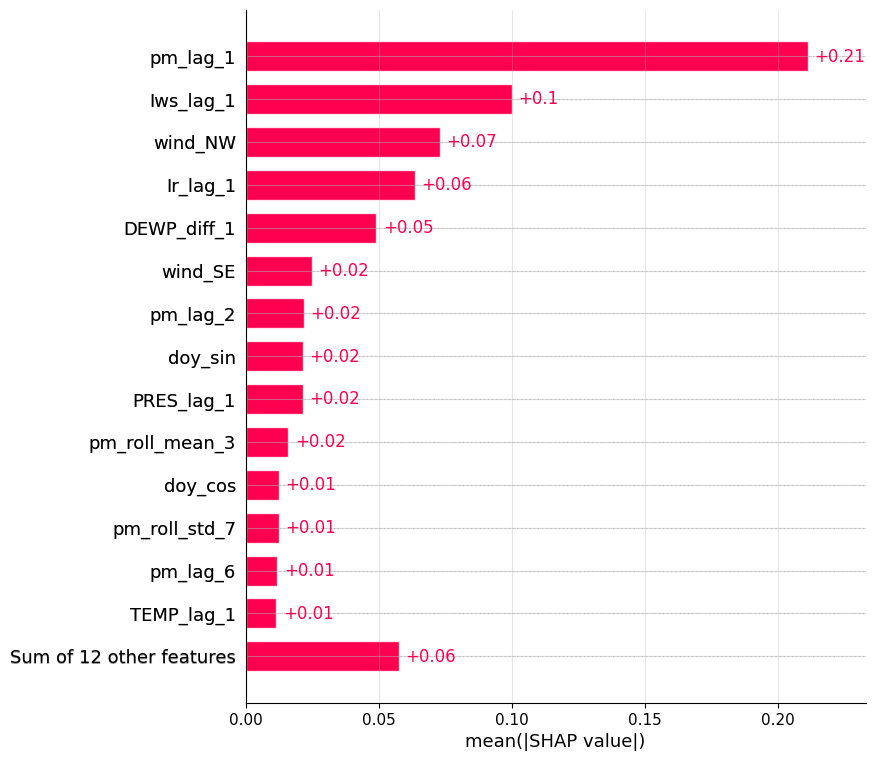

Top 10 features by mean |SHAP| (log1p units):


,mean |SHAP|
pm_lag_1,0.2113
Iws_lag_1,0.1001
wind_NW,0.0730
Ir_lag_1,0.0636
DEWP_diff_1,0.0491
wind_SE,0.0249
pm_lag_2,0.0220
doy_sin,0.0216
PRES_lag_1,0.0214
pm_roll_mean_3,0.0160


In [15]:
shap.plots.bar(shap_exp, max_display=15)

mean_abs = pd.Series(np.abs(shap_exp.values).mean(0), index=feature_names).sort_values(ascending=False)
print("Top 10 features by mean |SHAP| (log1p units):")
display(mean_abs.head(10).round(4).to_frame("mean |SHAP|"))

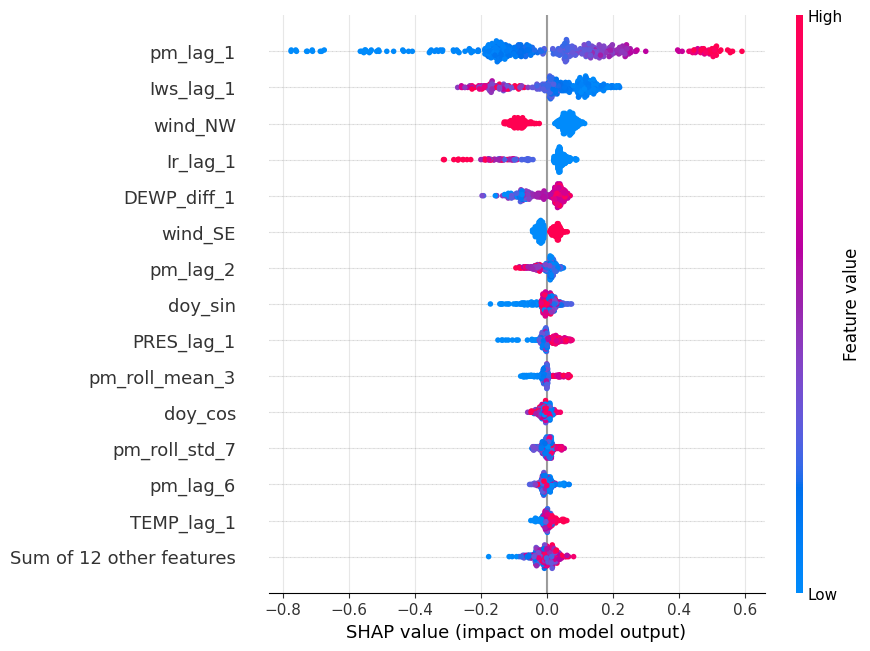

,mean|SHAP|,"rho(value, SHAP)",share SHAP>0
feature,,,
pm_lag_1,0.211,0.983,0.518
Iws_lag_1,0.100,-0.909,0.710
wind_NW,0.073,-0.819,0.663
Ir_lag_1,0.064,-0.688,0.805
DEWP_diff_1,0.049,0.849,0.573
wind_SE,0.025,0.861,0.447
pm_lag_2,0.022,-0.668,0.633
doy_sin,0.022,0.054,0.556
PRES_lag_1,0.021,0.751,0.499


,feature A,feature B,mean |interaction|
0,pm_lag_1,Iws_lag_1,0.0117
1,pm_lag_1,DEWP_diff_1,0.0109
2,Iws_lag_1,wind_NW,0.0102
3,Ir_lag_1,doy_sin,0.0093
4,pm_lag_1,wind_NW,0.0090
5,pm_lag_1,pm_lag_2,0.0070


pm_lag_2: Spearman(SHAP, pm_lag_2) = -0.67 | Spearman(SHAP, pm_lag_1/pm_lag_2) = 0.42
pm_lag_2 in its top quartile:  mean SHAP = -0.044 if lag_1 < lag_2 (falling), -0.019 if lag_1 >= lag_2 (rising)


In [16]:
shap.plots.beeswarm(shap_exp, max_display=15)

# direction: Spearman(feature value, SHAP value); sign consistency of the SHAP value
rows = []
for f in mean_abs.head(10).index:
    j = feature_names.index(f)
    sv, xv = shap_exp.values[:, j], X_test[f].values
    rho = spearmanr(xv, sv)[0] if np.std(xv) > 0 else np.nan
    rows.append({"feature": f, "mean|SHAP|": np.abs(sv).mean(), "rho(value, SHAP)": rho,
                 "share SHAP>0": (sv > 0).mean()})
direction = pd.DataFrame(rows).set_index("feature")
display(direction.round(3))

# conditional effects: strongest pairwise interactions
inter = tree_explainer.shap_interaction_values(X_test)
mi = np.abs(inter).mean(0); np.fill_diagonal(mi, 0)
pairs = [(feature_names[a], feature_names[b], mi[a, b]) for a in range(len(feature_names)) for b in range(a + 1, len(feature_names))]
display(pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:6], columns=["feature A", "feature B", "mean |interaction|"]).round(4))

# is pm_lag_2's effect conditional on pm_lag_1? (a high lag_2 only means "falling" if lag_1 is lower)
j2 = feature_names.index("pm_lag_2")
trend = (X_test["pm_lag_1"] / X_test["pm_lag_2"]).values            # < 1: pollution was falling yesterday
print("pm_lag_2: Spearman(SHAP, pm_lag_2) = %.2f | Spearman(SHAP, pm_lag_1/pm_lag_2) = %.2f" % (
    spearmanr(shap_exp.values[:, j2], X_test["pm_lag_2"])[0], spearmanr(shap_exp.values[:, j2], trend)[0]))
lo_, hi_ = X_test["pm_lag_2"] > X_test["pm_lag_2"].quantile(0.75), X_test["pm_lag_2"] < X_test["pm_lag_2"].quantile(0.25)
print("pm_lag_2 in its top quartile:  mean SHAP = %.3f if lag_1 < lag_2 (falling), %.3f if lag_1 >= lag_2 (rising)" % (
    shap_exp.values[lo_ & (trend < 1), j2].mean(), shap_exp.values[lo_ & (trend >= 1), j2].mean()))

**C2 — Your answer:**

The top five features by mean |SHAP| are `pm_lag_1` (0.211), `Iws_lag_1` (0.100), `wind_NW` (0.073), `Ir_lag_1` (0.064) and `DEWP_diff_1` (0.049), which matches four of my five prior entries almost exactly in rank and sign; the one difference is that humidity enters through its *change* (`DEWP_diff_1`) and `DEWP_lag_1` is nearly unused (0.009). Every weather feature in the top ten has the physically expected direction (Spearman ρ between feature value and SHAP): `Iws_lag_1` −0.91, `wind_NW` −0.82, `Ir_lag_1` −0.69, `DEWP_diff_1` +0.85, `wind_SE` +0.86 and `PRES_lag_1` +0.75 (high pressure means stagnation). The effect of `pm_lag_2` is *conditional*, like `lag_2` in the lecture: its SHAP falls with its own value (ρ = −0.67) because, given `pm_lag_1`, a high lag 2 means pollution was already falling, and its SHAP correlates with the ratio `pm_lag_1/pm_lag_2` (ρ = +0.42). `doy_sin` is another conditional case (mean |SHAP| 0.022 but ρ = +0.05): its sign depends on other inputs, e.g. its interaction with `Ir_lag_1` (0.0093); the largest interactions are `pm_lag_1` × `Iws_lag_1` (0.0117) and `Iws_lag_1` × `wind_NW` (0.0102).

### C3 (5 marks)
Choose three test days:
1. the most polluted **forecast**,
2. the day with the largest absolute **error**,
3. the day with the largest one-day **drop** in actual PM2.5 (a clean-air event).

Draw a waterfall plot for each. For the clean-air day: did the model anticipate the drop, and which inputs pushed it down? If it missed, what information was it lacking?

most polluted forecast   2014-10-11 | actual  197.6 | forecast  210.6 | yesterday  325.4 µg/m³
largest abs. error       2014-01-16 | actual  457.5 | forecast  128.0 | yesterday  191.8 µg/m³
largest 1-day drop       2014-02-27 | actual   19.9 | forecast  114.8 | yesterday  407.7 µg/m³
(waterfall values are in log1p units)


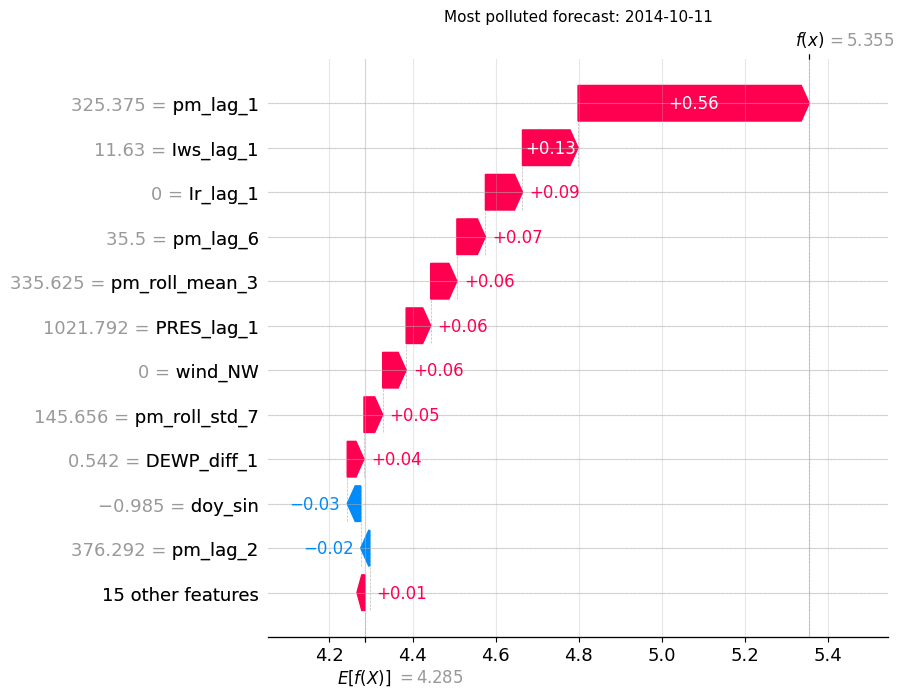

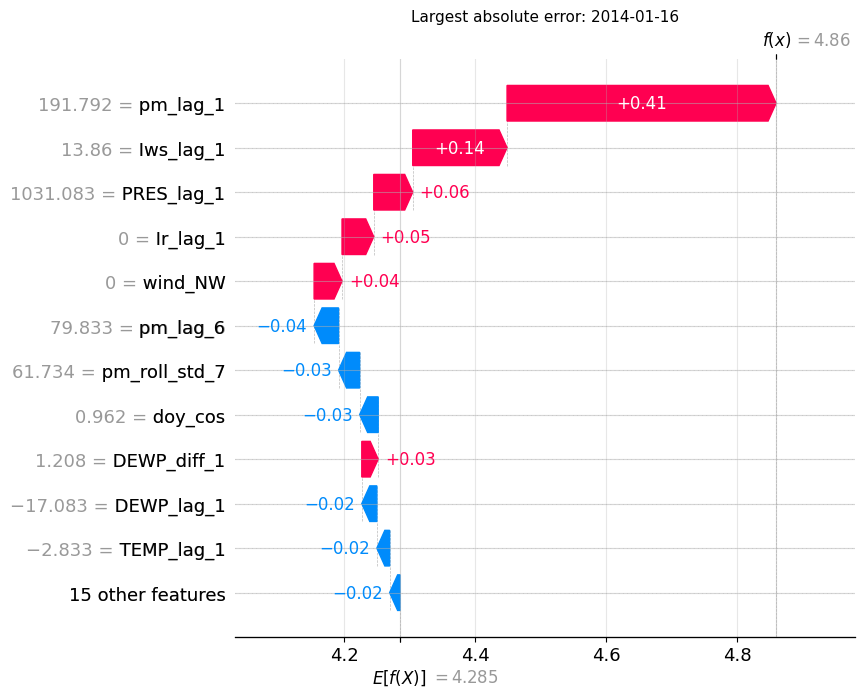

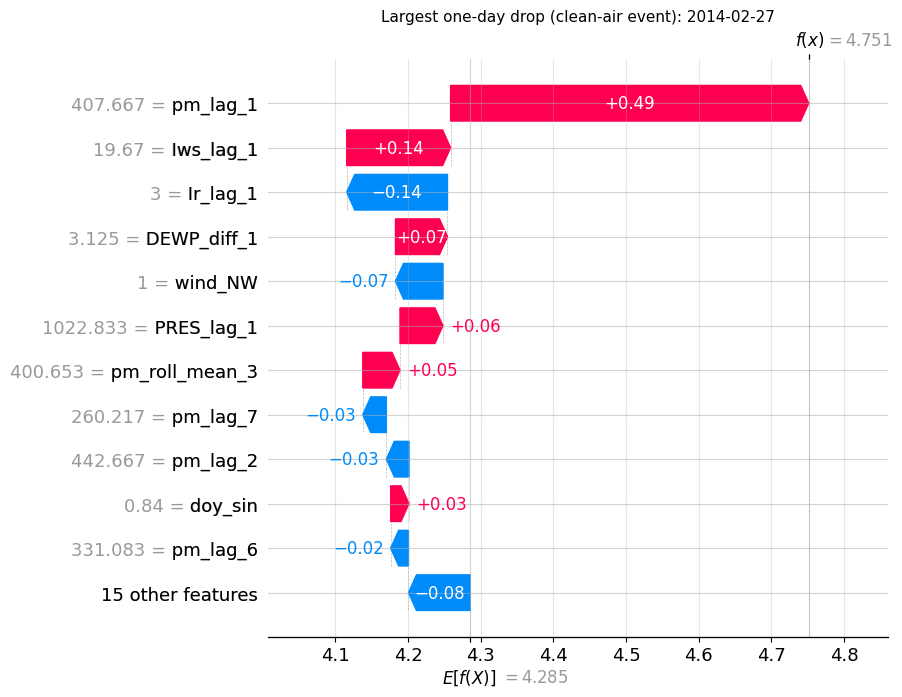


Clean-air day, strongest negative SHAP:


,phi
Ir_lag_1,-0.139
wind_NW,-0.065
pm_lag_7,-0.032
pm_lag_2,-0.031
pm_lag_6,-0.025


Clean-air day, strongest positive SHAP:


,phi
pm_roll_mean_3,0.051
PRES_lag_1,0.059
DEWP_diff_1,0.072
Iws_lag_1,0.143
pm_lag_1,0.493


{'pm_lag_1': 407.67, 'pm_lag_2': 442.67, 'Iws_lag_1': 19.67, 'DEWP_lag_1': -1.17, 'PRES_lag_1': 1022.83, 'PRES_diff_1': -3.21, 'wind_NW': 1.0, 'wind_cv': 0.0}

Most polluted forecast, strongest SHAP contributions (log1p units):


,phi
pm_lag_1,0.556
Iws_lag_1,0.134
Ir_lag_1,0.089
pm_lag_6,0.069
pm_roll_mean_3,0.063
PRES_lag_1,0.059


as multiplicative factors on the forecast: exp(phi) = {'pm_lag_1': 1.74, 'Iws_lag_1': 1.14, 'Ir_lag_1': 1.09, 'pm_lag_6': 1.07}
most polluted : actual  197.6 | honest model  210.6 | oracle model  217.6 µg/m³
largest error : actual  457.5 | honest model  128.0 | oracle model  281.5 µg/m³
largest drop  : actual   19.9 | honest model  114.8 | oracle model   32.8 µg/m³
clean-air day, weather of day t vs day t-1: {'Iws': (84.0, 19.7), 'DEWP': (-16.4, -1.2), 'PRES': (1028.6, 1022.8)} | wind at t: ['NW'] | wind at t-1: ['NW']


In [17]:
pos_high = int(np.argmax(pred_lgbm_ug))
pos_err = int(np.argmax(np.abs(pred_lgbm_ug - y_test_ug.values)))
drop = y_test_ug.values - X_test["pm_lag_1"].values          # actual change from yesterday
pos_drop = int(np.argmin(drop))
idx_high, idx_err, idx_drop = pos_high, pos_err, pos_drop     # integer positions in the test set

for name, i in [("most polluted forecast", idx_high), ("largest abs. error", idx_err), ("largest 1-day drop", idx_drop)]:
    print(f"{name:24s} {X_test.index[i].date()} | actual {y_test_ug.values[i]:6.1f} | forecast {pred_lgbm_ug[i]:6.1f} | yesterday {X_test['pm_lag_1'].values[i]:6.1f} µg/m³")
print("(waterfall values are in log1p units)")

for name, i in [("Most polluted forecast", idx_high), ("Largest absolute error", idx_err), ("Largest one-day drop (clean-air event)", idx_drop)]:
    shap.plots.waterfall(shap_exp[i], max_display=12, show=False)
    plt.title(f"{name}: {X_test.index[i].date()}", fontsize=11); plt.show()

# what pushed the clean-air day down / up
sv = pd.Series(shap_exp.values[idx_drop], index=feature_names).sort_values()
print("\nClean-air day, strongest negative SHAP:"); display(sv.head(5).round(3).to_frame("phi"))
print("Clean-air day, strongest positive SHAP:"); display(sv.tail(5).round(3).to_frame("phi"))
print(X_test.iloc[idx_drop][["pm_lag_1", "pm_lag_2", "Iws_lag_1", "DEWP_lag_1", "PRES_lag_1", "PRES_diff_1", "wind_NW", "wind_cv"]].round(2).to_dict())

ph = pd.Series(shap_exp.values[idx_high], index=feature_names)
print("\nMost polluted forecast, strongest SHAP contributions (log1p units):")
display(ph.reindex(ph.abs().sort_values(ascending=False).index).head(6).round(3).to_frame("phi"))
print("as multiplicative factors on the forecast: exp(phi) =", {k: round(float(np.exp(v)), 2) for k, v in ph.reindex(ph.abs().sort_values(ascending=False).index).head(4).items()})

# did the day-t weather (which the honest model cannot see) matter? ask the B4 oracle model
for name, i in [("most polluted", idx_high), ("largest error", idx_err), ("largest drop", idx_drop)]:
    print(f"{name:14s}: actual {y_test_ug.values[i]:6.1f} | honest model {pred_lgbm_ug[i]:6.1f} | oracle model {pred_oracle_ug[i]:6.1f} µg/m³")
print("clean-air day, weather of day t vs day t-1:", {c: (round(float(X_test_o.iloc[idx_drop][c + "_t"]), 1), round(float(X_test_o.iloc[idx_drop][c + "_lag_1"]), 1)) for c in ["Iws", "DEWP", "PRES"]},
      "| wind at t:", [w for w in WINDS if X_test_o.iloc[idx_drop][f"wind_{w}_t"] == 1], "| wind at t-1:", [w for w in WINDS if X_test_o.iloc[idx_drop][f"wind_{w}"] == 1])

**C3 — Your answer:**

The most polluted forecast is 2014-10-11 (forecast 210.6, actual 197.6 µg/m³): `pm_lag_1` = 325 µg/m³ contributes +0.556 (a factor 1.74), then low yesterday's wind `Iws_lag_1` (+0.134) and no rain (+0.089). The largest error is 2014-01-16 (forecast 128.0, actual 457.5), a smog build-up that nothing in the previous day's data announced. On the clean-air day, 2014-02-27, PM2.5 fell from 407.7 to 19.9 µg/m³ and the model only **half-anticipated** it (forecast 114.8, a 72% fall instead of 95%): `Ir_lag_1` (−0.139) and `wind_NW` (−0.065) pushed it down, but `pm_lag_1` (+0.493) and the low `Iws_lag_1` = 19.7 (+0.143) pulled it back up. What the model lacked is the weather of that day: the oracle model, which sees day-t weather, forecasts 32.8 µg/m³, because wind speed jumped from 19.7 to 84.0 and the dew point fell from −1.2 to −16.4 °C, the signature of a dry north-westerly front.

### C4 (4 marks)
Draw two dependence plots: `Iws_lag_1` coloured by the NW wind indicator, and `pm_lag_1` coloured by `DEWP_lag_1`. Describe the shape of each learned response curve (linear, saturating, threshold) and the interaction the colour reveals.

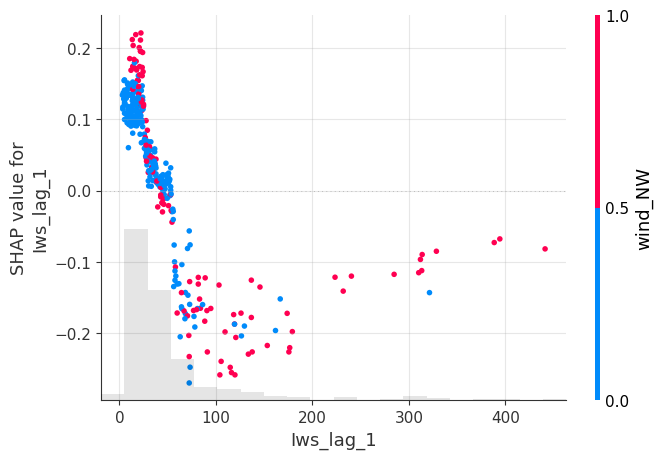

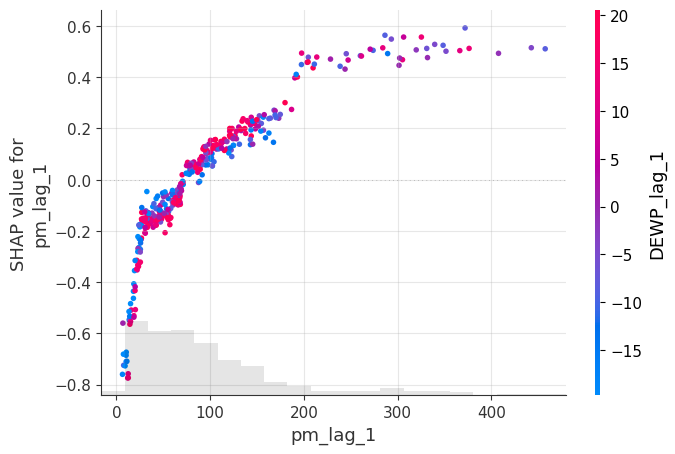

Iws_lag_1: mean SHAP by quantile bin, split by yesterday's wind = NW (1) or not (0)


mean        count    
g                   0.0    1.0   0.0 1.0
bin                                     
(3.119, 13.86]    0.121  0.177    58   4
(13.86, 22.343]   0.118  0.170    38  22
(22.343, 31.75]   0.072  0.099    40  23
(31.75, 45.14]    0.024  0.009    45  15
(45.14, 72.137]  -0.046 -0.085    46  13
(72.137, 441.18] -0.171 -0.165    15  46

pm_lag_1: mean SHAP by quantile bin, split by DEWP_lag_1 above median (1) or not (0)


mean        count    
g                                 0      1     0   1
bin                                                 
(6.4159999999999995, 29.651] -0.408 -0.403    37  24
(29.651, 53.0]               -0.110 -0.159    27  34
(53.0, 77.667]               -0.048 -0.071    25  36
(77.667, 104.556]             0.058  0.088    30  30
(104.556, 151.028]            0.153  0.179    21  40
(151.028, 457.5]              0.380  0.459    43  18

In [18]:
shap.plots.scatter(shap_exp[:, "Iws_lag_1"], color=shap_exp[:, "wind_NW"])
shap.plots.scatter(shap_exp[:, "pm_lag_1"], color=shap_exp[:, "DEWP_lag_1"])

# numeric description of the curves
def binned(feature, split, q=6):
    j = feature_names.index(feature)
    d = pd.DataFrame({"x": X_test[feature].values, "phi": shap_exp.values[:, j], "g": split})
    d["bin"] = pd.qcut(d["x"], q, duplicates="drop")
    return d.groupby(["bin", "g"], observed=True)["phi"].agg(["mean", "count"]).unstack("g").round(3)

print("Iws_lag_1: mean SHAP by quantile bin, split by yesterday's wind = NW (1) or not (0)")
display(binned("Iws_lag_1", X_test["wind_NW"].values))
dew_hi = (X_test["DEWP_lag_1"] > X_test["DEWP_lag_1"].median()).astype(int).values
print("pm_lag_1: mean SHAP by quantile bin, split by DEWP_lag_1 above median (1) or not (0)")
display(binned("pm_lag_1", dew_hi))

**C4 — Your answer:**

`Iws_lag_1` has a saturating, decreasing response: mean SHAP is about +0.12 to +0.18 below 14 m/s, crosses zero near 32–45 m/s, reaches −0.05 to −0.09 at 45–72 m/s and levels off near −0.17 above 72 m/s. The colour shows an interaction with the NW indicator: at low wind speed NW days have a higher Iws contribution (+0.177 vs +0.121 in the lowest bin), partly offsetting the −0.07 that `wind_NW` already gives, while above 72 m/s both groups sit at about −0.17 (and 46 of the 61 strongest-wind days are NW). `pm_lag_1` has a near log-linear, S-shaped response, from −0.41 (below 30 µg/m³) through zero at about 80 µg/m³ to +0.38 to +0.46 (above 150). Humid days (DEWP above median) have a steeper curve: +0.459 vs +0.380 in the top bin and −0.159 vs −0.110 in the 30–53 bin, so humidity amplifies the persistence effect in both directions.

### C5 (5 marks) — grouped and seasonal SHAP
Sum SHAP values within each group of `FEATURE_GROUPS`. Plot:
- (a) mean |grouped SHAP| as a bar chart,
- (b) a month × group heatmap of mean |grouped SHAP| for 2014.

Is the model mainly a persistence model or a weather model? Does reliance on weather change between the heating and non-heating seasons?

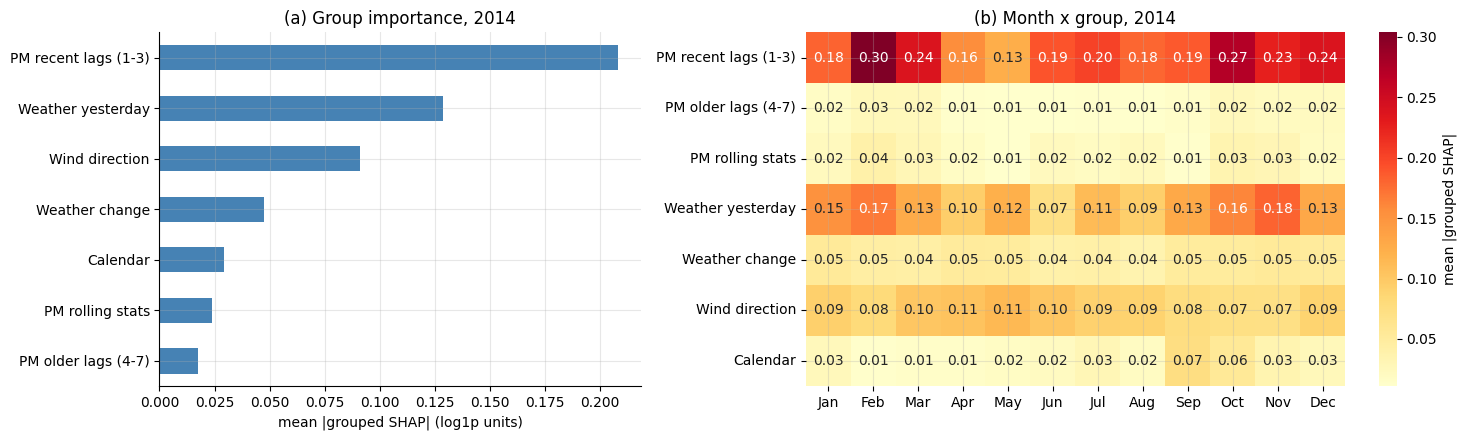

share of total group importance (%):


,%
PM recent lags (1-3),38.1
Weather yesterday,23.6
Wind direction,16.6
Weather change,8.7
Calendar,5.3
PM rolling stats,4.3
PM older lags (4-7),3.2


persistence groups: 45.7% | weather groups: 49.0% | calendar: 5.3%
days: heating = 121, non-heating = 244


,heating,non-heating,ratio heating/non-heating
PM recent lags (1-3),0.235,0.195,1.203
PM older lags (4-7),0.023,0.015,1.498
PM rolling stats,0.028,0.021,1.318
Weather yesterday,0.157,0.115,1.373
Weather change,0.051,0.046,1.121
Wind direction,0.088,0.092,0.947
Calendar,0.022,0.033,0.672


heating     : weather share = 49.1% | persistence share = 47.3%
non-heating : weather share = 48.9% | persistence share = 44.8%


In [19]:
def grouped(values, names, groups):
    return pd.DataFrame({g: values[:, [names.index(f) for f in fs]].sum(axis=1) for g, fs in groups.items()})

group_shap = grouped(shap_exp.values, feature_names, FEATURE_GROUPS)
group_shap.index = X_test.index

gm = group_shap.abs().mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
gm.plot.barh(ax=axes[0], color="steelblue"); axes[0].set_xlabel("mean |grouped SHAP| (log1p units)"); axes[0].set_title("(a) Group importance, 2014")
hm = group_shap.abs().groupby(group_shap.index.month).mean()
hm.index = [pd.Timestamp(2014, m, 1).strftime("%b") for m in hm.index]
sns.heatmap(hm.T, cmap="YlOrRd", annot=True, fmt=".2f", ax=axes[1], cbar_kws={"label": "mean |grouped SHAP|"})
axes[1].set_title("(b) Month x group, 2014"); plt.tight_layout(); plt.show()

share = (gm / gm.sum() * 100).sort_values(ascending=False)
print("share of total group importance (%):"); display(share.round(1).to_frame("%"))
pers = ["PM recent lags (1-3)", "PM older lags (4-7)", "PM rolling stats"]
wthr = ["Weather yesterday", "Weather change", "Wind direction"]
print(f"persistence groups: {gm[pers].sum() / gm.sum() * 100:.1f}% | weather groups: {gm[wthr].sum() / gm.sum() * 100:.1f}% | calendar: {gm['Calendar'] / gm.sum() * 100:.1f}%")

heating = (X_test["is_heating_season"] == 1).values
season = pd.DataFrame({"heating": group_shap[heating].abs().mean(), "non-heating": group_shap[~heating].abs().mean()})
season["ratio heating/non-heating"] = season["heating"] / season["non-heating"]
print(f"days: heating = {heating.sum()}, non-heating = {(~heating).sum()}")
display(season.round(3))
for lab, m in [("heating", heating), ("non-heating", ~heating)]:
    a = group_shap[m].abs().mean()
    print(f"{lab:12s}: weather share = {a[wthr].sum() / a.sum() * 100:.1f}% | persistence share = {a[pers].sum() / a.sum() * 100:.1f}%")

**C5 — Your answer:**

By group, the PM recent lags give 38.1% of the total mean |grouped SHAP|, weather yesterday 23.6%, wind direction 16.6%, weather change 8.7%, calendar 5.3%, rolling stats 4.3% and older lags 3.2%. Summed over groups, persistence is 45.7% and weather is 49.0%, so the model is a **persistence-anchored weather model**: a single feature (`pm_lag_1`) is the largest, but the weather groups together carry slightly more than all the PM2.5 history. Reliance on weather does not change *relatively* between seasons (weather share 49.1% in the 121 heating days vs 48.9% in the 244 other days), but in absolute terms the model leans harder on yesterday's weather and on PM lags in the heating season (weather yesterday 0.157 vs 0.115, ×1.37; recent lags ×1.20), while wind direction is the same (0.088 vs 0.092) and the calendar matters less (×0.67). The heatmap shows the highest weather-yesterday values in Nov (0.18) and Feb (0.17) and the lowest in June (0.07).

### C6 (3 marks) — explaining the oracle
Repeat C5(a) for `lgbm_oracle` from B4. How does the importance of the PM2.5 lags change when the model can see day *t*'s weather? Explain what this shows about how correlated inputs share credit.

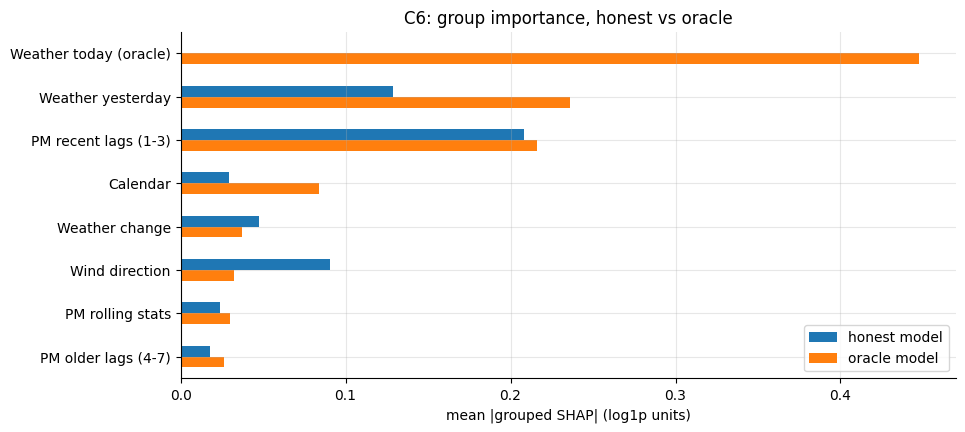

,honest model,oracle model,change %
Weather today (oracle),0.000,0.447,NaN
Weather yesterday,0.129,0.236,83.310
PM recent lags (1-3),0.208,0.216,3.871
Calendar,0.029,0.084,189.632
Weather change,0.048,0.037,-22.203
Wind direction,0.091,0.032,-64.554
PM rolling stats,0.024,0.030,26.260
PM older lags (4-7),0.018,0.026,48.164


pm_lag_1 mean|SHAP|: honest 0.211 -> oracle 0.219
persistence share: honest 45.7% -> oracle 24.5%
Spearman of pm_lag_1 with day-t weather / target: {'DEWP_t': -0.0, 'Iws_t': -0.0, 'PRES_t': 0.11, 'target': 0.48}


,today (oracle),"Spearman(a, b)","mean|SHAP| a, honest","mean|SHAP| a, oracle","mean|SHAP| b, oracle"
yesterday,,,,,
Iws_lag_1,Iws_t,0.408,0.100,0.053,0.158
DEWP_lag_1,DEWP_t,0.943,0.009,0.085,0.199
PRES_lag_1,PRES_t,0.915,0.021,0.072,0.094
wind_NW,wind_NW_t,0.252,0.073,0.015,0.098
wind_SE,wind_SE_t,0.246,0.025,0.018,0.042


In [20]:
tree_explainer_o = shap.TreeExplainer(lgbm_oracle)
sv_o = tree_explainer_o.shap_values(X_test_o)
group_shap_o = grouped(sv_o, feature_names_o, FEATURE_GROUPS_O)

cmp = pd.DataFrame({"honest model": group_shap.abs().mean(), "oracle model": group_shap_o.abs().mean()}).fillna(0)
cmp["change %"] = (cmp["oracle model"] / cmp["honest model"].replace(0, np.nan) - 1) * 100
cmp = cmp.sort_values("oracle model", ascending=False)
ax = cmp[["honest model", "oracle model"]].plot.barh(figsize=(10, 4.5)); ax.invert_yaxis()
ax.set_xlabel("mean |grouped SHAP| (log1p units)"); ax.set_title("C6: group importance, honest vs oracle"); plt.show()
display(cmp.round(3))

j = feature_names_o.index("pm_lag_1")
print(f"pm_lag_1 mean|SHAP|: honest {np.abs(shap_exp.values[:, feature_names.index('pm_lag_1')]).mean():.3f} -> oracle {np.abs(sv_o[:, j]).mean():.3f}")
tot_h, tot_o = group_shap.abs().mean().sum(), group_shap_o.abs().mean().sum()
print(f"persistence share: honest {group_shap.abs().mean()[pers].sum() / tot_h * 100:.1f}% -> oracle {group_shap_o.abs().mean()[pers].sum() / tot_o * 100:.1f}%")
# why: yesterday's PM2.5 and today's weather are correlated
tmp = X_test_o.assign(target=y_test.values)
print("Spearman of pm_lag_1 with day-t weather / target:", {c: round(float(spearmanr(tmp["pm_lag_1"], tmp[c])[0]), 2) for c in ["DEWP_t", "Iws_t", "PRES_t", "target"]})
# yesterday's weather vs today's weather: these ARE strongly correlated, so they split / hand over credit
pairs_c = [("Iws_lag_1", "Iws_t"), ("DEWP_lag_1", "DEWP_t"), ("PRES_lag_1", "PRES_t"), ("wind_NW", "wind_NW_t"), ("wind_SE", "wind_SE_t")]
rows = []
for a, b in pairs_c:
    rows.append({"yesterday": a, "today (oracle)": b, "Spearman(a, b)": spearmanr(tmp[a], tmp[b])[0],
                 "mean|SHAP| a, honest": np.abs(shap_exp.values[:, feature_names.index(a)]).mean(),
                 "mean|SHAP| a, oracle": np.abs(sv_o[:, feature_names_o.index(a)]).mean(),
                 "mean|SHAP| b, oracle": np.abs(sv_o[:, feature_names_o.index(b)]).mean()})
display(pd.DataFrame(rows).set_index("yesterday").round(3))

**C6 — Your answer:**

When the model sees day-t weather, the absolute importance of the PM2.5 lags hardly changes (recent-lag group 0.208 → 0.216, `pm_lag_1` 0.211 → 0.219), but their share of the total falls from 45.7% to 24.5%, because the new "weather today" group alone takes 0.447. The lags keep their credit because `pm_lag_1` is almost uncorrelated with day-t weather (|ρ| ≤ 0.11), so nothing competes with it. Credit moves between inputs that carry the same information: yesterday's wind direction group drops by 65% (`wind_NW` 0.073 → 0.015) while `wind_NW_t` gets 0.098, and `Iws_lag_1` falls from 0.100 to 0.053 while `Iws_t` gets 0.158. `DEWP_lag_1` and `DEWP_t` (ρ = 0.94) both gain importance (0.085 and 0.199), which is consistent with the model using the pair as a change in dew point. This shows that Shapley values split credit among correlated inputs, so a feature's importance depends on which other features are in the model, not only on its own causal role.

---
# Part D: LIME (15 marks)

In [21]:
def predict_fn(arr):
    return lgbm.predict(pd.DataFrame(arr, columns=feature_names))

### D1 (4 marks)
Explain the most polluted forecast and the clean-air day from C3 with `LimeTabularExplainer` (5,000 samples). Report the black-box forecast, LIME's surrogate prediction and the local R² for each. Which of the two explanations would you trust more, and why?

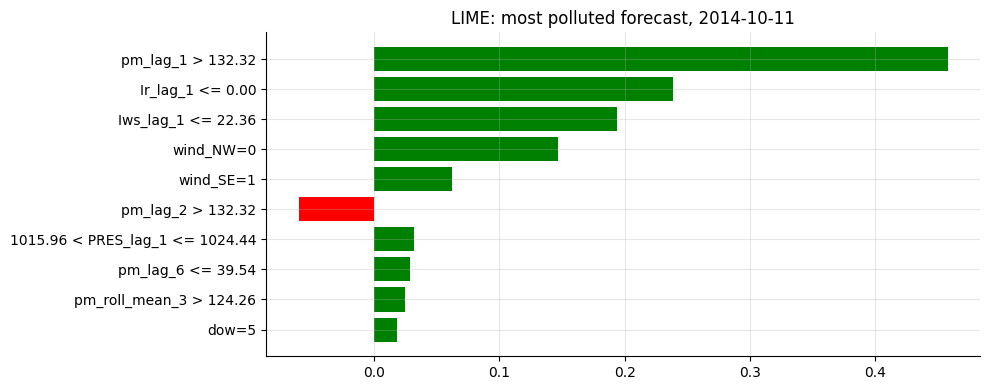

most polluted forecast -> [('pm_lag_1 > 132.32', 0.458), ('Ir_lag_1 <= 0.00', 0.239), ('Iws_lag_1 <= 22.36', 0.194), ('wind_NW=0', 0.147), ('wind_SE=1', 0.062), ('pm_lag_2 > 132.32', -0.06)]


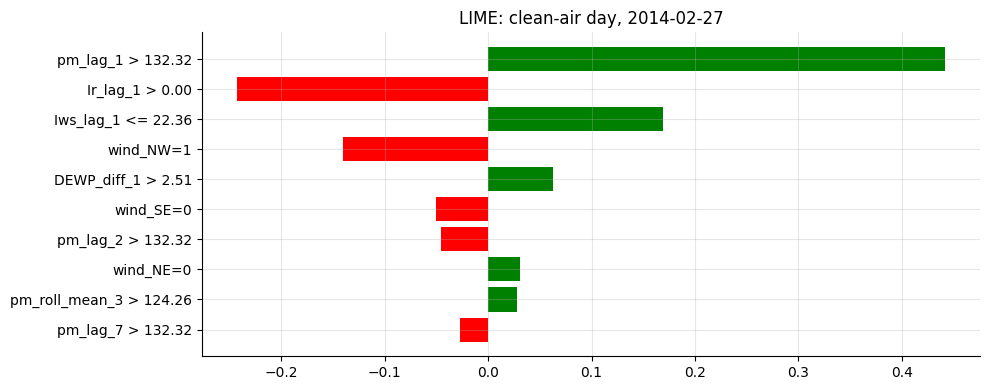

clean-air day -> [('pm_lag_1 > 132.32', 0.442), ('Ir_lag_1 > 0.00', -0.243), ('Iws_lag_1 <= 22.36', 0.169), ('wind_NW=1', -0.14), ('DEWP_diff_1 > 2.51', 0.063), ('wind_SE=0', -0.05)]


,black-box (µg/m³),LIME surrogate (µg/m³),black-box (log1p),surrogate (log1p),local R²
day,,,,,
most polluted forecast (2014-10-11),210.622,137.912,5.355,4.934,0.530
clean-air day (2014-02-27),114.756,84.138,4.751,4.444,0.527


In [22]:
cat_idx = [feature_names.index(f) for f in FEATURE_GROUPS["Wind direction"] + ["is_heating_season", "dow"]]
lime_explainer = LimeTabularExplainer(X_train.values, feature_names=feature_names, categorical_features=cat_idx,
                                      mode="regression", discretize_continuous=True, random_state=SEED)

def lime_explain(i, explainer=lime_explainer, n=5000, num_features=10):
    return explainer.explain_instance(X_test.values[i], predict_fn, num_features=num_features, num_samples=n)

d1 = []
for name, i in [("most polluted forecast", idx_high), ("clean-air day", idx_drop)]:
    exp = lime_explain(i)
    bb, sur = float(predict_fn(X_test.values[i:i + 1])[0]), float(exp.local_pred[0])
    d1.append({"day": f"{name} ({X_test.index[i].date()})", "black-box (µg/m³)": to_ug(bb), "LIME surrogate (µg/m³)": to_ug(sur),
               "black-box (log1p)": bb, "surrogate (log1p)": sur, "local R²": exp.score})
    fig = exp.as_pyplot_figure(); fig.set_size_inches(10, 4); plt.title(f"LIME: {name}, {X_test.index[i].date()}"); plt.tight_layout(); plt.show()
    print(name, "->", [(f, round(w, 3)) for f, w in exp.as_list()][:6])
display(pd.DataFrame(d1).set_index("day").round(3))

**D1 — Your answer:**

For the most polluted day (2014-10-11) the black box forecasts 210.6 µg/m³ while the LIME surrogate predicts 137.9 µg/m³ (−35%), with a local R² of 0.530. For the clean-air day (2014-02-27) the black box gives 114.8 and LIME 84.1 µg/m³ (−27%), with R² = 0.527. Both explanations name the same ingredients as SHAP (`pm_lag_1 > 132` +0.46 and +0.44, `Ir_lag_1` −0.24 on the clean-air day, `wind_NW=1` −0.14), but the surrogate explains only about half of the local variance and under-predicts the forecast. I would trust the **clean-air day** explanation slightly more, because its surrogate error is smaller and its signs agree with SHAP, but neither is reliable: the "`pm_lag_1` > 132" bin lumps 325 and 408 µg/m³ together, and the R² is measured on LIME's own perturbations, which D2 shows are mostly unrealistic.

### D2 (4 marks) — unrealistic neighbours
Generate LIME's perturbation samples for one instance (or reproduce LIME's sampling yourself) and count the fraction of neighbours that are **physically implausible**. Define implausible with at least two rules you justify, for example:
- `pm_lag_1` more than 3 × `pm_roll_mean_3` (impossible by construction),
- snow hours > 0 with `TEMP_lag_1` > 10 °C.

Explain why this matters more for time series than for ordinary tabular data.

In [23]:
WIND_COLS = FEATURE_GROUPS["Wind direction"]

def violations(df):
    v = pd.DataFrame(index=df.index)
    v["R1 pm_lag_1 > 3 x roll_mean_3"] = df["pm_lag_1"] > 3 * df["pm_roll_mean_3"] + 1e-6
    v["R2 snow hours > 0 and TEMP > 10C"] = (df["Is_lag_1"] > 0) & (df["TEMP_lag_1"] > 10)
    v["R3 dew point > temperature"] = df["DEWP_lag_1"] > df["TEMP_lag_1"] + 1e-6
    v["R4 wind one-hot not exactly one"] = df[WIND_COLS].round().sum(axis=1) != 1
    m3 = df[["pm_lag_1", "pm_lag_2", "pm_lag_3"]].mean(axis=1)
    v["R5 roll_mean_3 off from lags by >25%"] = (df["pm_roll_mean_3"] - m3).abs() > 0.25 * np.maximum(m3, 1)
    v["R6 (doy_sin, doy_cos) off unit circle"] = (df["doy_sin"] ** 2 + df["doy_cos"] ** 2 - 1).abs() > 0.05
    return v

x0 = X_test.values[idx_high]
_, inverse = lime_explainer._LimeTabularExplainer__data_inverse(x0, 5000)     # LIME's own perturbation samples
neigh = pd.DataFrame(inverse[1:], columns=feature_names)
v_neigh, v_real = violations(neigh), violations(X_test)
tab = pd.DataFrame({"LIME neighbours": v_neigh.mean(), "real test days": v_real.mean()}) * 100
tab.loc["ANY rule violated"] = [v_neigh.any(axis=1).mean() * 100, v_real.any(axis=1).mean() * 100]
print(f"Instance: {X_test.index[idx_high].date()} | {len(neigh)} neighbours | percentage violating each rule:")
display(tab.round(1))
print("example neighbour:", neigh.iloc[0][["pm_lag_1", "pm_lag_2", "pm_lag_3", "pm_roll_mean_3", "TEMP_lag_1", "DEWP_lag_1", "Is_lag_1"] + WIND_COLS].round(1).to_dict())

Instance: 2014-10-11 | 4999 neighbours | percentage violating each rule:


,LIME neighbours,real test days
R1 pm_lag_1 > 3 x roll_mean_3,13.3,0.0
R2 snow hours > 0 and TEMP > 10C,2.0,0.0
R3 dew point > temperature,30.5,0.0
R4 wind one-hot not exactly one,53.5,0.0
R5 roll_mean_3 off from lags by >25%,75.4,0.0
"R6 (doy_sin, doy_cos) off unit circle",89.5,0.0
ANY rule violated,99.3,0.0


example neighbour: {'pm_lag_1': 46.0, 'pm_lag_2': 97.8, 'pm_lag_3': 12.3, 'pm_roll_mean_3': 38.0, 'TEMP_lag_1': -1.6, 'DEWP_lag_1': 17.6, 'Is_lag_1': 0.0, 'wind_NW': 0.0, 'wind_NE': 0.0, 'wind_SE': 0.0, 'wind_cv': 0.0}


**D2 — Your answer:**

Of the 4,999 neighbours LIME generated around 2014-10-11, **99.3%** violate at least one of six rules, against 0% of the real test days. The most common violations are (R6) `doy_sin`/`doy_cos` off the unit circle, 89.5%; (R5) `pm_roll_mean_3` more than 25% away from the mean of the three lags, 75.4%; (R4) wind one-hot columns that are not exactly one, 53.5%; (R3) dew point above temperature, 30.5%; (R1) `pm_lag_1` > 3 × `pm_roll_mean_3`, which is impossible by construction, 13.3%; and (R2) snow with temperature above 10 °C, 2.0%. This matters more for time series because the features are deterministic functions of one underlying series (lags, rolling statistics, a calendar angle, a one-hot), so perturbing them independently breaks identities that hold in all real data. The model is queried in regions it never saw, and the local R² and weights then describe behaviour on impossible days rather than around the real forecast.

### D3 (4 marks) — stability
Re-run LIME 15 times with different seeds, using **500** and **5,000** samples, on the same instance. Show a boxplot of the weights for the top eight features and a table of the coefficient of variation. List the features whose **sign** flips across seeds.

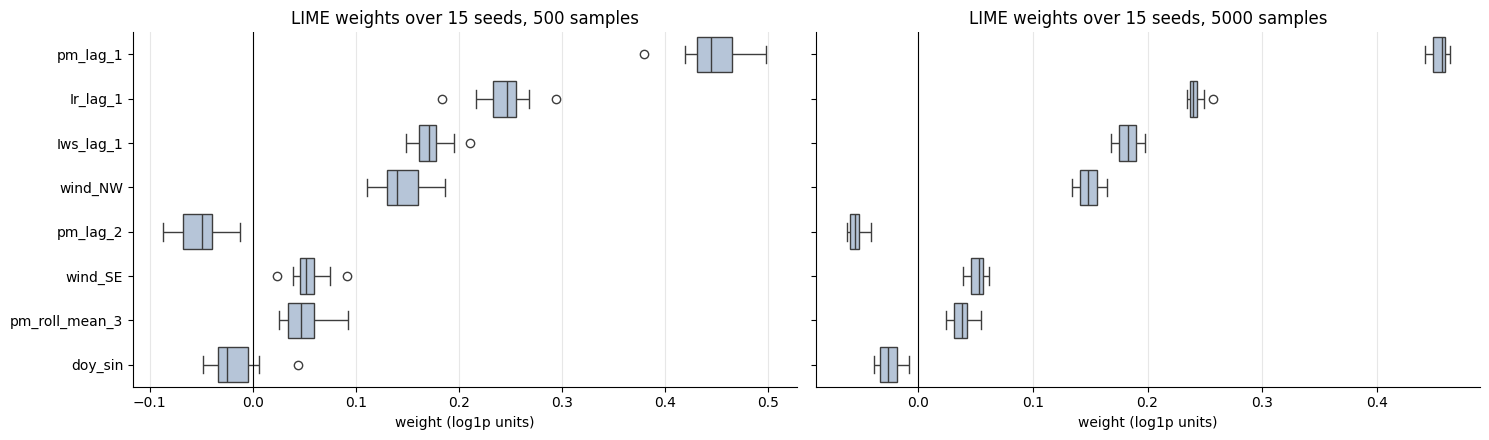

,CV @ 500,CV @ 5000,mean weight @ 5000
pm_lag_1,0.06,0.01,0.45
Ir_lag_1,0.10,0.02,0.24
Iws_lag_1,0.09,0.05,0.18
wind_NW,0.15,0.06,0.15
pm_lag_2,0.44,0.12,-0.05
wind_SE,0.30,0.13,0.05
pm_roll_mean_3,0.40,0.23,0.04
doy_sin,1.34,0.38,-0.03


  500 samples: 18 of 26 features flip sign; among top 8: ['doy_sin']
        all flippers: ['pm_lag_3', 'pm_lag_4', 'pm_lag_5', 'pm_lag_6', 'pm_roll_mean_7', 'pm_roll_std_7', 'DEWP_lag_1', 'TEMP_lag_1', 'PRES_lag_1', 'Is_lag_1', 'PRES_diff_1', 'DEWP_diff_1', 'wind_NE', 'wind_cv', 'doy_sin', 'doy_cos', 'is_heating_season', 'dow']
 5000 samples: 17 of 26 features flip sign; among top 8: []
        all flippers: ['pm_lag_3', 'pm_lag_4', 'pm_lag_5', 'pm_lag_6', 'pm_lag_7', 'pm_roll_mean_7', 'pm_roll_std_7', 'DEWP_lag_1', 'TEMP_lag_1', 'Is_lag_1', 'PRES_diff_1', 'DEWP_diff_1', 'wind_NE', 'wind_cv', 'doy_cos', 'is_heating_season', 'dow']
mean CV over the top 8: {500: 0.36, 5000: 0.13}


In [24]:
def lime_weights(i, seed, n):
    ex = LimeTabularExplainer(X_train.values, feature_names=feature_names, categorical_features=cat_idx,
                              mode="regression", discretize_continuous=True, random_state=seed)
    e = ex.explain_instance(X_test.values[i], predict_fn, num_features=len(feature_names), num_samples=n)
    return {feature_names[j]: w for j, w in e.local_exp[1]}      # key 1 = the surrogate's own weights (regression mode)

SEEDS = [SEED + k for k in range(15)]
W3 = {n: pd.DataFrame([lime_weights(idx_high, s, n) for s in SEEDS], index=SEEDS)[feature_names] for n in (500, 5000)}
top8 = W3[5000].abs().mean().sort_values(ascending=False).head(8).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, n in zip(axes, (500, 5000)):
    sns.boxplot(data=W3[n][top8], orient="h", ax=ax, color="lightsteelblue"); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"LIME weights over 15 seeds, {n} samples"); ax.set_xlabel("weight (log1p units)")
plt.tight_layout(); plt.show()

cv = pd.DataFrame({f"CV @ {n}": W3[n][top8].std() / W3[n][top8].mean().abs() for n in (500, 5000)})
cv["mean weight @ 5000"] = W3[5000][top8].mean()
display(cv.round(2))
for n in (500, 5000):
    flips = [f for f in feature_names if (W3[n][f] > 0).any() and (W3[n][f] < 0).any()]
    flips_top = [f for f in flips if f in top8]
    print(f"{n:5d} samples: {len(flips)} of {len(feature_names)} features flip sign; among top 8: {flips_top}")
    print("        all flippers:", flips)
print("mean CV over the top 8:", {n: round(float((W3[n][top8].std() / W3[n][top8].mean().abs()).mean()), 2) for n in (500, 5000)})

**D3 — Your answer:**

With 15 seeds on the most polluted day, the top-eight weights are much more stable at 5,000 samples than at 500: the coefficient of variation falls from 0.06 to 0.01 for `pm_lag_1`, 0.10 to 0.02 for `Ir_lag_1`, 0.09 to 0.05 for `Iws_lag_1`, 0.15 to 0.06 for `wind_NW`, and 0.44 to 0.12 for `pm_lag_2`; the mean over the eight drops from 0.36 to 0.13, and `doy_sin` stays unreliable (1.34 → 0.38). Sign flips are common in the tail: 18 of 26 features change sign across seeds at 500 samples (among the top eight only `doy_sin`) and 17 of 26 at 5,000 (none of the top eight). The flippers are small-weight features such as lags 3–7, `dow`, `is_heating_season`, `wind_cv` and the weather-change features. In practice, the first four LIME features are dependable, the tail is noise, and a low sample count makes even the middle of the ranking unstable.

### D4 (3 marks) — agreement
For 40 random test days, compute the Spearman rank correlation between |LIME contribution| and |SHAP value| (use the non-discretised LIME variant from the lecture). Report the mean and plot the histogram. Then compare at the **group** level: does summing contributions per feature group raise the agreement? Explain the result.

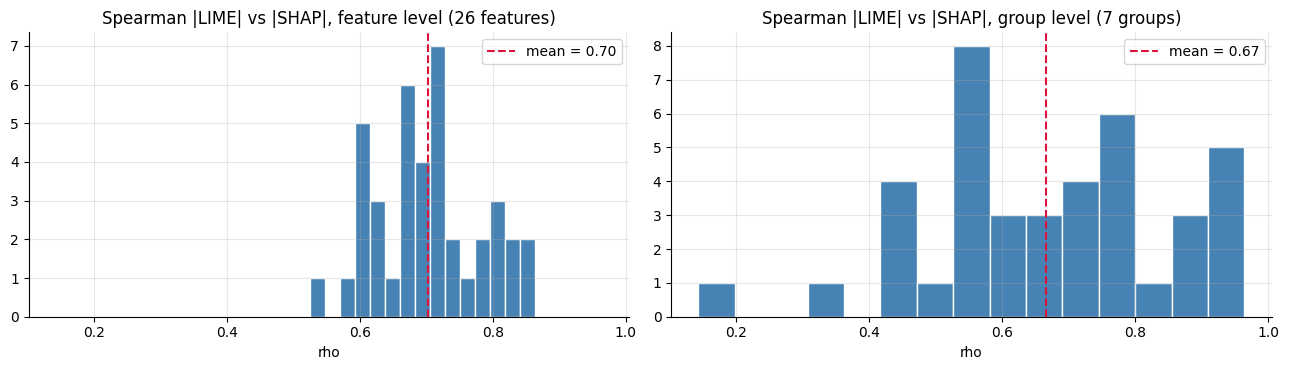

feature level: mean rho = 0.703, median = 0.703, min = 0.53
group level  : mean rho = 0.665, median = 0.679, min = 0.14
group-level beats feature-level on 50% of the 40 days


In [25]:
# non-discretised LIME: surrogate is linear in standardised features, contribution_j = w_j * (x_j - mean_j) / scale_j
nd_explainer = LimeTabularExplainer(X_train.values, feature_names=feature_names, mode="regression",
                                    discretize_continuous=False, random_state=SEED)
F = len(feature_names)
rng = np.random.default_rng(SEED)
days = rng.choice(len(X_test), 40, replace=False)
gidx = {g: [feature_names.index(f) for f in fs] for g, fs in FEATURE_GROUPS.items()}

rho_feat, rho_grp, lime_contribs = [], [], []
for i in days:
    e = nd_explainer.explain_instance(X_test.values[i], predict_fn, num_features=F, num_samples=5000)
    w = np.zeros(F)
    for j, wt in e.local_exp[1]:
        w[j] = wt
    contrib = w * (X_test.values[i] - nd_explainer.scaler.mean_) / nd_explainer.scaler.scale_
    phi = shap_exp.values[i]
    lime_contribs.append(contrib)
    rho_feat.append(spearmanr(np.abs(contrib), np.abs(phi))[0])
    rho_grp.append(spearmanr([abs(contrib[ix].sum()) for ix in gidx.values()], [abs(phi[ix].sum()) for ix in gidx.values()])[0])

rho_feat, rho_grp = np.array(rho_feat), np.array(rho_grp)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for ax, r, t in zip(axes, (rho_feat, rho_grp), ("feature level (%d features)" % F, "group level (7 groups)")):
    ax.hist(r, bins=15, color="steelblue", edgecolor="w"); ax.axvline(np.nanmean(r), color="crimson", ls="--", label=f"mean = {np.nanmean(r):.2f}")
    ax.set_title(f"Spearman |LIME| vs |SHAP|, {t}"); ax.set_xlabel("rho"); ax.legend()
plt.tight_layout(); plt.show()
print(f"feature level: mean rho = {np.nanmean(rho_feat):.3f}, median = {np.nanmedian(rho_feat):.3f}, min = {np.nanmin(rho_feat):.2f}")
print(f"group level  : mean rho = {np.nanmean(rho_grp):.3f}, median = {np.nanmedian(rho_grp):.3f}, min = {np.nanmin(rho_grp):.2f}")
print(f"group-level beats feature-level on {(rho_grp > rho_feat).mean() * 100:.0f}% of the 40 days")

**D4 — Your answer:**

On 40 random test days the mean Spearman correlation between |LIME contribution| and |SHAP value| over the 26 features is **0.703** (median 0.703, minimum 0.53), a moderate agreement. At the group level (7 groups, signed contributions summed within each group) the mean is **0.665** (median 0.679, minimum 0.14), and group level beats feature level on only 50% of the days. So summing per group does *not* raise the agreement. A rank correlation over 7 items is very noisy (a single swapped pair changes it a lot). Summing signed contributions also lets opposite effects cancel inside a group, and LIME's local linear surrogate cannot reproduce the interaction effects that SHAP distributes. The two methods agree on which few features matter most, and disagree on the order of the rest.

---
# Part E: A sequence model and attribution methods (15 marks)

### E1 (3 marks)
Build input windows of **W = 14** days with **six channels** per step: scaled `log1p(PM2.5)`, `DEWP`, `PRES`, `Iws`, `doy_sin`, `doy_cos`. Fit all scalers on the training years only. Train a small LSTM or 1-D CNN with early stopping on 2013, and add its test MAE (µg/m³) to the table from B3.

windows: (1811, 14, 6) | train 1081 val 365 test 365


stopped at epoch 47, best epoch 27, best val MSE (standardised log units) = 0.5776


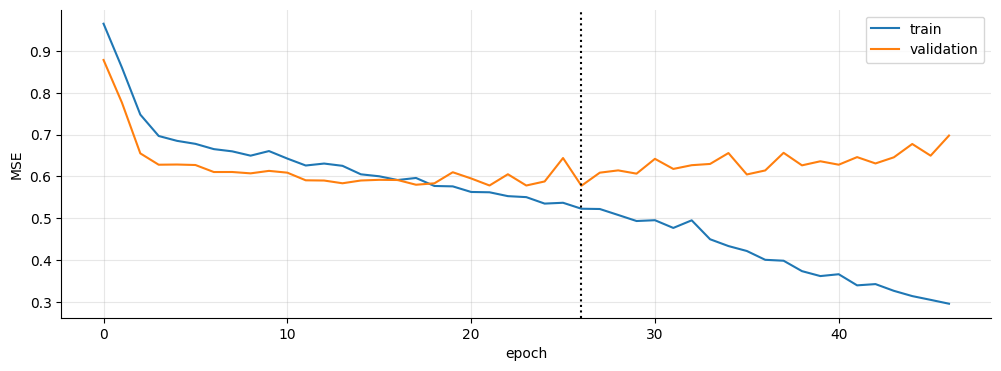

,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.10,67.16
LightGBM oracle (day-t weather),28.84,42.02
LSTM (14-day window),45.90,65.12


In [26]:
W = 14
CHANNELS = ["log_pm", "DEWP", "PRES", "Iws", "doy_sin", "doy_cos"]

doy = daily_clean.index.dayofyear
seq_raw = pd.DataFrame({
    "log_pm": np.log1p(daily_clean["pm2.5"]), "DEWP": daily_clean["DEWP"], "PRES": daily_clean["PRES"], "Iws": daily_clean["Iws"],
    "doy_sin": np.sin(2 * np.pi * doy / 365.25), "doy_cos": np.cos(2 * np.pi * doy / 365.25)}, index=daily_clean.index)[CHANNELS]

# scalers are fitted on the training years only
train_days = seq_raw.index <= "2012-12-31"
mu, sd = seq_raw[train_days].mean(), seq_raw[train_days].std()
Z = ((seq_raw - mu) / sd).values.astype(np.float32)

# window for target day t = days t-W ... t-1 (nothing from day t)
Xs, ys, dts = [], [], []
for t in range(W, len(Z)):
    win = Z[t - W:t]
    if np.isnan(win).any() or np.isnan(Z[t, 0]):
        continue
    Xs.append(win); ys.append(Z[t, 0]); dts.append(seq_raw.index[t])
X_seq, y_seq, seq_dates = np.stack(Xs), np.array(ys, dtype=np.float32), pd.DatetimeIndex(dts)
m_tr, m_va, m_te = seq_dates <= "2012-12-31", seq_dates.year == 2013, seq_dates.year == 2014
assert (seq_dates[m_te] == X_test.index).all(), "LSTM and LightGBM must be evaluated on the same days"
Xtr_t, Xva_t, Xte_t = (torch.tensor(X_seq[m]) for m in (m_tr, m_va, m_te))
ytr_t, yva_t = torch.tensor(y_seq[m_tr]), torch.tensor(y_seq[m_va])
print("windows:", X_seq.shape, "| train", len(Xtr_t), "val", len(Xva_t), "test", len(Xte_t))

class SeqForecaster(nn.Module):
    def __init__(self, n_in=len(CHANNELS), hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 24), nn.ReLU(), nn.Linear(24, 1))
    def forward(self, x):          # x: (batch, W, channels)
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)

torch.manual_seed(SEED)
model = SeqForecaster()
opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-5)
gen = torch.Generator().manual_seed(SEED)
best, best_state, wait, PATIENCE, hist = 1e9, None, 0, 20, []
for epoch in range(300):
    model.train()
    perm = torch.randperm(len(Xtr_t), generator=gen)
    for b in perm.split(64):
        opt.zero_grad()
        loss = nn.functional.mse_loss(model(Xtr_t[b]), ytr_t[b])
        loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        tr_l, va_l = nn.functional.mse_loss(model(Xtr_t), ytr_t).item(), nn.functional.mse_loss(model(Xva_t), yva_t).item()
    hist.append((tr_l, va_l))
    if va_l < best - 1e-5:
        best, best_state, wait, best_epoch = va_l, {k: v.clone() for k, v in model.state_dict().items()}, 0, epoch
    else:
        wait += 1
        if wait >= PATIENCE:
            break
model.load_state_dict(best_state); model.eval()
for p in model.parameters():
    p.requires_grad_(False)
print(f"stopped at epoch {epoch + 1}, best epoch {best_epoch + 1}, best val MSE (standardised log units) = {best:.4f}")
plt.plot([h[0] for h in hist], label="train"); plt.plot([h[1] for h in hist], label="validation")
plt.axvline(best_epoch, color="k", ls=":"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

def seq_to_ug(z):
    """standardised log_pm -> µg/m³"""
    return np.expm1(z * sd["log_pm"] + mu["log_pm"])

with torch.no_grad():
    pred_lstm_ug = seq_to_ug(model(Xte_t).numpy())
y_te_ug = seq_to_ug(y_seq[m_te])
assert np.allclose(y_te_ug, y_test_ug.values, rtol=1e-4)
results.loc["LSTM (14-day window)"] = pd.Series(metrics(y_te_ug, pred_lstm_ug)).round(2)
results

**E1 — Your answer:**

The sequence model is a one-layer LSTM (48 hidden units) with a small ReLU head, fed 14-day windows of six channels (`log1p` PM2.5, DEWP, PRES, Iws, `doy_sin`, `doy_cos`) scaled with 2010–2012 statistics only, and the window ends on day t−1. Early stopping on the 2013 windows stopped training at epoch 47 and restored epoch 27 (validation MSE 0.578 in standardised log units). Its 2014 test MAE is **45.90 µg/m³** (RMSE 65.12), against 45.10 / 67.16 for LightGBM, 52.75 / 75.71 for persistence and 28.84 / 42.02 for the oracle. The LSTM has a slightly higher MAE (+0.8) but a lower RMSE (−2.0) than LightGBM, so with only four real inputs it reaches about the same skill as the 26 engineered features, which suggests that most of the usable information is already in the last days of PM2.5 and wind.

### E2 (5 marks)
Implement **from scratch in PyTorch** (no Captum): Saliency, Gradient × Input, SmoothGrad and Integrated Gradients. Use the average training window as the IG baseline. Verify IG **completeness** numerically and report the mean gap. Then compute GradientSHAP with `shap.GradientExplainer` and 200 background windows.

In [27]:
BASELINE = Xtr_t.mean(0, keepdim=True)   # (1, W, C) average training window

def _grad(x):
    """gradient of the summed model output w.r.t. the input"""
    x = x.clone().detach().requires_grad_(True)
    g, = torch.autograd.grad(model(x).sum(), x)
    return g

def saliency(x):
    return _grad(x).abs()

def grad_x_input(x):
    return _grad(x) * x

def smoothgrad(x, n=30, sigma=0.15):
    gen = torch.Generator().manual_seed(SEED)
    span = (x.amax(dim=(1, 2), keepdim=True) - x.amin(dim=(1, 2), keepdim=True))
    total = torch.zeros_like(x)
    for _ in range(n):
        total += _grad(x + torch.randn(x.shape, generator=gen) * sigma * span).abs()
    return total / n

def integrated_gradients(x, baseline=BASELINE, steps=64):
    b = baseline.expand_as(x)
    total = torch.zeros_like(x)
    for k in range(steps):                       # midpoint rule
        total += _grad(b + (k + 0.5) / steps * (x - b))
    return (x - b) * total / steps

ATTR = {}
ATTR["Saliency"] = saliency(Xte_t).numpy()
ATTR["Grad x Input"] = grad_x_input(Xte_t).numpy()
ATTR["SmoothGrad"] = smoothgrad(Xte_t).numpy()
ATTR["Integrated Gradients"] = integrated_gradients(Xte_t).numpy()

# --- IG completeness: sum(attr) = f(x) - f(baseline)
with torch.no_grad():
    delta = (model(Xte_t) - model(BASELINE.expand_as(Xte_t))).numpy()
ig_sum = ATTR["Integrated Gradients"].sum((1, 2))
ig_gap = np.abs(ig_sum - delta)
print(f"IG completeness: mean |sum(attr) - (f(x)-f(b))| = {ig_gap.mean():.5f} | max = {ig_gap.max():.5f} | mean |f(x)-f(b)| = {np.abs(delta).mean():.3f}")
for steps in (8, 16, 64, 256):
    g = np.abs(integrated_gradients(Xte_t[:100], steps=steps).numpy().sum((1, 2)) - delta[:100]).mean()
    print(f"   steps = {steps:3d}: mean gap = {g:.5f}")

# --- GradientSHAP (shap.GradientExplainer, 200 background windows)
class _Out2D(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x).unsqueeze(-1)

np.random.seed(SEED); torch.manual_seed(SEED)
bg = Xtr_t[torch.randperm(len(Xtr_t), generator=torch.Generator().manual_seed(SEED))[:200]]
gs = shap.GradientExplainer(_Out2D(model), bg)
sv_gs = gs.shap_values(Xte_t)
sv_gs = np.asarray(sv_gs[0] if isinstance(sv_gs, list) else sv_gs)
if sv_gs.ndim == 4:
    sv_gs = sv_gs[..., 0]
ATTR["GradientSHAP"] = sv_gs
with torch.no_grad():
    exp_bg = model(bg).mean().item()
gap_gs = np.abs(sv_gs.sum((1, 2)) - (model(Xte_t).numpy() - exp_bg))
print(f"GradientSHAP: shape {sv_gs.shape} | mean |sum(phi) - (f(x) - E[f(bg)])| = {gap_gs.mean():.4f}")
print({k: v.shape for k, v in ATTR.items()})

IG completeness: mean |sum(attr) - (f(x)-f(b))| = 0.00073 | max = 0.00477 | mean |f(x)-f(b)| = 0.536
   steps =   8: mean gap = 0.00471
   steps =  16: mean gap = 0.00214


   steps =  64: mean gap = 0.00061


   steps = 256: mean gap = 0.00015


GradientSHAP: shape (365, 14, 6) | mean |sum(phi) - (f(x) - E[f(bg)])| = 0.0511
{'Saliency': (365, 14, 6), 'Grad x Input': (365, 14, 6), 'SmoothGrad': (365, 14, 6), 'Integrated Gradients': (365, 14, 6), 'GradientSHAP': (365, 14, 6)}


**E2 — Your answer:**

Saliency, Gradient × Input, SmoothGrad (30 noisy copies, σ = 0.15 of the input range) and Integrated Gradients (64 midpoint steps, average training window as baseline) are written from scratch with `torch.autograd.grad`. IG completeness holds: the mean gap |Σ attribution − (f(x) − f(baseline))| over the 365 test windows is **0.00073** (maximum 0.0048), about 0.14% of the mean |f(x) − f(b)| = 0.536, and it shrinks with the step count (0.0047 at 8 steps, 0.0021 at 16, 0.0006 at 64 and 0.00015 at 256), as expected for a Riemann-sum error. GradientSHAP with 200 background windows reports a larger mean gap of 0.051 relative to f(x) − E[f(background)], which is normal for a sampled estimate and not a bug. Saliency and SmoothGrad are unsigned sensitivities, so completeness does not apply to them.

### E3 (3 marks)
Implement **Occlusion** (window k = 2 days, all channels) and a **segment-based LIME** (7 segments of 2 days, baseline replacement, weighted ridge).

In [28]:
def occlusion(x, k=2, baseline=BASELINE):
    """Replace k consecutive days (all channels) by the baseline; attribution = drop in forecast, shared over the k days.
    Overlapping windows (stride 1): every day gets the average over the windows that cover it. Returns (n, W)."""
    with torch.no_grad():
        f0 = model(x)
        contrib, cnt = torch.zeros(x.shape[0], x.shape[1]), torch.zeros(x.shape[1])
        for s in range(x.shape[1] - k + 1):
            xo = x.clone(); xo[:, s:s + k, :] = baseline[:, s:s + k, :]
            contrib[:, s:s + k] += ((f0 - model(xo)) / k)[:, None]
            cnt[s:s + k] += 1
    return (contrib / cnt).numpy()

def lime_segments(x, n_seg=7, n_samples=600, kernel_width=0.35, baseline=BASELINE, seed=SEED):
    """Segment-based LIME: switch segments of W/n_seg days on (keep) or off (baseline), weighted ridge. Returns (n, W)."""
    rng = np.random.default_rng(seed)
    seg = x.shape[1] // n_seg
    Z = np.ones((n_samples, n_seg), dtype=np.float32)
    for r in range(1, n_samples):                                   # row 0 = the instance itself
        Z[r, rng.choice(n_seg, rng.integers(1, n_seg), replace=False)] = 0
    dist = np.sqrt((1 - Z).sum(1) / n_seg)                         # sqrt(fraction of segments removed)
    wts = np.exp(-dist ** 2 / kernel_width ** 2)
    keep = torch.tensor(np.repeat(Z, seg, axis=1))[:, :, None]      # (n_samples, W, 1)
    out = np.zeros((x.shape[0], x.shape[1]), dtype=np.float32)
    with torch.no_grad():
        for i in range(x.shape[0]):
            y = model(torch.where(keep > 0, x[i:i + 1], baseline)).numpy()
            coef = Ridge(alpha=1.0).fit(Z, y, sample_weight=wts).coef_
            out[i] = np.repeat(coef / seg, seg)
    return out

ATTR_T = {}                                                   # per-time-step attribution, signed (n, W)
ATTR_ABS_T = {}                                               # sum over channels of |attribution| (n, W)
for name, a in ATTR.items():
    ATTR_T[name] = a.sum(2); ATTR_ABS_T[name] = np.abs(a).sum(2)
ATTR_T["Occlusion"] = occlusion(Xte_t)
ATTR_T["Segment-LIME"] = lime_segments(Xte_t)
for name in ("Occlusion", "Segment-LIME"):
    ATTR_ABS_T[name] = np.abs(ATTR_T[name])
METHODS = list(ATTR_T)
print(METHODS)

# sanity: segment-LIME / occlusion should roughly add up to f(x) - f(baseline)
print("sum of Occlusion attr vs f(x)-f(b): corr = %.2f | sum of Segment-LIME attr vs f(x)-f(b): corr = %.2f" % (
    np.corrcoef(ATTR_T["Occlusion"].sum(1), delta)[0, 1], np.corrcoef(ATTR_T["Segment-LIME"].sum(1), delta)[0, 1]))

['Saliency', 'Grad x Input', 'SmoothGrad', 'Integrated Gradients', 'GradientSHAP', 'Occlusion', 'Segment-LIME']
sum of Occlusion attr vs f(x)-f(b): corr = 0.84 | sum of Segment-LIME attr vs f(x)-f(b): corr = 0.98


**E3 — Your answer:**

Occlusion (k = 2, stride 1, all channels replaced by the baseline; each day gets the average over the windows covering it) and segment-LIME (7 segments of 2 days, 600 samples, kernel width 0.35, weighted ridge) are implemented above and give one attribution per time step. As a sanity check, the sum of the segment-LIME attributions correlates 0.98 with f(x) − f(baseline) (it is almost additive), and the sum of the occlusion attributions 0.84 (overlapping windows make it only approximately additive). Both attribute to whole days or segments, so segment-LIME gives the same value to both days of a segment, which limits its resolution (visible in E4 and F2).

### E4 (4 marks)
For the model's largest-error test day, plot:
- (a) the 14-day input history,
- (b) a methods × time-step heatmap of attributions summed over channels, normalised per row,
- (c) an Integrated Gradients **time × channel** heatmap.

Which channel and which day drove that forecast? Does the explanation agree with the domain hints?

> **Baseline question.** The average training window means "a typical fortnight of pollution and weather." Is this a sensible baseline for pollution, given its heavy right skew and strong winter/summer difference? Propose one alternative baseline and say how it would change the meaning of the attributions.

Largest LSTM test error: 2014-12-09 | actual 348.5 | forecast 55.8 µg/m³ | error 292.7


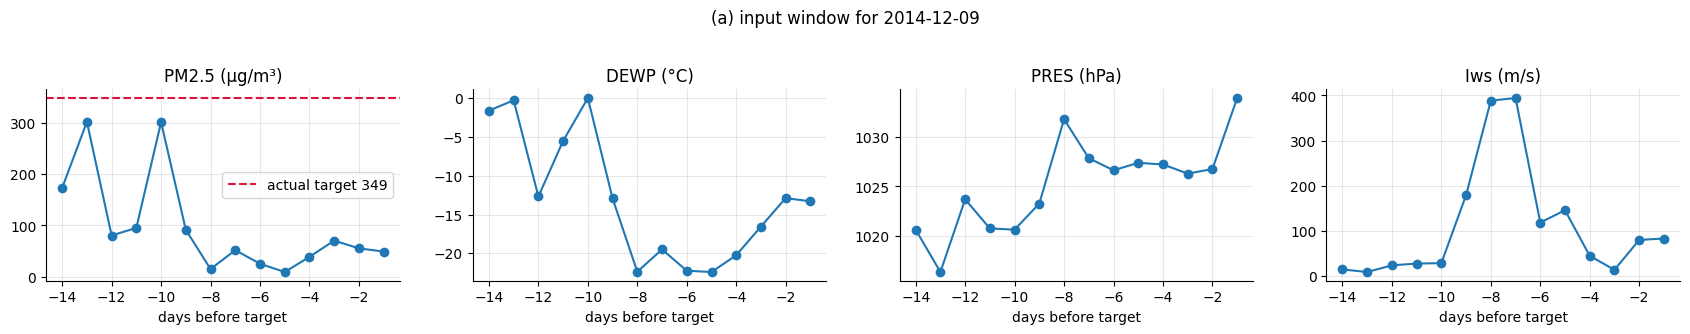

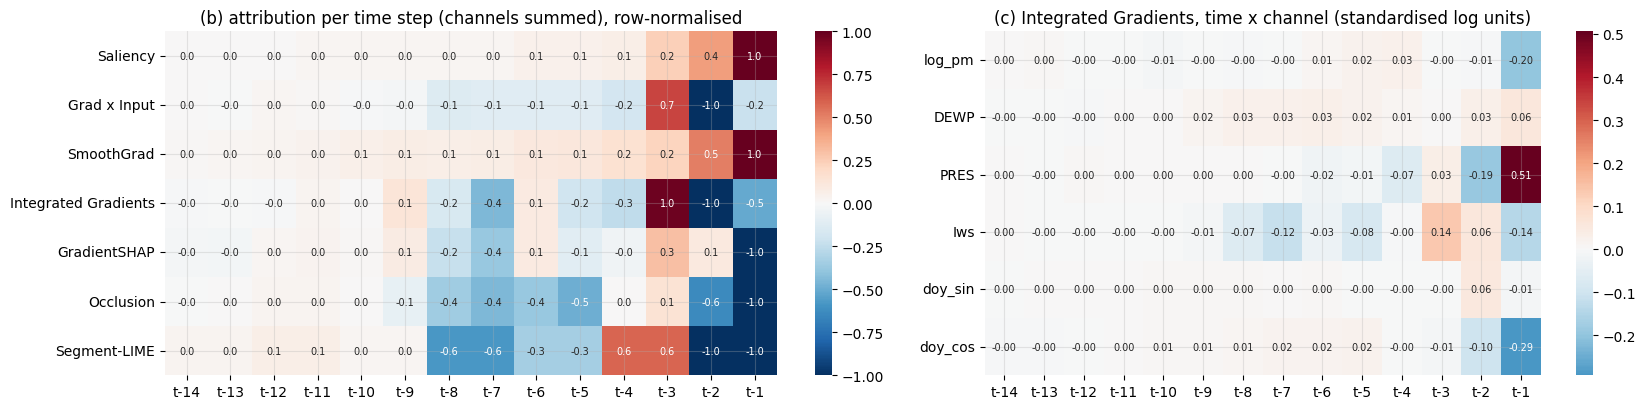

IG per channel (summed over time): {'log_pm': -0.15800000727176666, 'DEWP': 0.21899999678134918, 'PRES': 0.2549999952316284, 'Iws': -0.2630000114440918, 'doy_sin': 0.06599999964237213, 'doy_cos': -0.335999995470047}
largest single IG cell: channel PRES at t-1 = 0.506
IG per day (summed over channels), t-14 .. t-1: [-0.0, -0.0, -0.0, 0.0, 0.0, 0.019999999552965164, -0.029999999329447746, -0.07000000029802322, 0.009999999776482582, -0.029999999329447746, -0.03999999910593033, 0.1599999964237213, -0.1599999964237213, -0.07999999821186066]
sum IG = -0.218 = f(x) - f(baseline) = -0.219
window in original units, last 3 days: {'PM2.5': [71.0, 55.0, 49.0], 'DEWP': [-16.5, -12.9, -13.3], 'Iws': [13.9, 80.0, 83.2]}
baseline window: mean PM2.5 (geometric) = 72 µg/m³, DEWP = 2.2, PRES = 1016, Iws = 64.6
tabular LGBM forecast for the same day: 58.7 µg/m³


In [29]:
abs_err = np.abs(pred_lstm_ug - y_te_ug)
i_e = int(np.argmax(abs_err))
print(f"Largest LSTM test error: {X_test.index[i_e].date()} | actual {y_te_ug[i_e]:.1f} | forecast {pred_lstm_ug[i_e]:.1f} µg/m³ | error {abs_err[i_e]:.1f}")

# (a) the 14-day input history in original units
hist_days = pd.date_range(end=X_test.index[i_e] - pd.Timedelta(days=1), periods=W)
win_raw = X_seq[m_te][i_e] * sd.values + mu.values
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, (c, vals, unit) in zip(axes, [("PM2.5", np.expm1(win_raw[:, 0]), "µg/m³"), ("DEWP", win_raw[:, 1], "°C"),
                                       ("PRES", win_raw[:, 2], "hPa"), ("Iws", win_raw[:, 3], "m/s")]):
    ax.plot(range(-W, 0), vals, "o-"); ax.set_title(f"{c} ({unit})"); ax.set_xlabel("days before target")
axes[0].axhline(y_te_ug[i_e], color="crimson", ls="--", label=f"actual target {y_te_ug[i_e]:.0f}"); axes[0].legend()
plt.suptitle(f"(a) input window for {X_test.index[i_e].date()}", y=1.03); plt.tight_layout(); plt.show()

# (b) methods x time-step heatmap (channels summed), normalised per row
H = np.stack([ATTR_T[m][i_e] for m in METHODS]); H = H / np.abs(H).max(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(H, cmap="RdBu_r", center=0, vmin=-1, vmax=1, yticklabels=METHODS, xticklabels=[f"t-{W - k}" for k in range(W)], ax=axes[0], annot=True, fmt=".1f", annot_kws={"size": 7})
axes[0].set_title("(b) attribution per time step (channels summed), row-normalised")
# (c) IG time x channel
ig = ATTR["Integrated Gradients"][i_e]
sns.heatmap(ig.T, cmap="RdBu_r", center=0, yticklabels=CHANNELS, xticklabels=[f"t-{W - k}" for k in range(W)], ax=axes[1], annot=True, fmt=".2f", annot_kws={"size": 7})
axes[1].set_title("(c) Integrated Gradients, time x channel (standardised log units)")
plt.tight_layout(); plt.show()

ch_tot = pd.Series(ig.sum(0), index=CHANNELS)
t_idx, c_idx = np.unravel_index(np.argmax(np.abs(ig)), ig.shape)
print("IG per channel (summed over time):", ch_tot.round(3).to_dict())
print(f"largest single IG cell: channel {CHANNELS[c_idx]} at t-{W - t_idx} = {ig[t_idx, c_idx]:.3f}")
print("IG per day (summed over channels), t-14 .. t-1:", ig.sum(1).round(2).tolist())
print(f"sum IG = {ig.sum():.3f} = f(x) - f(baseline) = {delta[i_e]:.3f}")
print("window in original units, last 3 days:", {"PM2.5": np.expm1(win_raw[-3:, 0]).round(0).tolist(), "DEWP": win_raw[-3:, 1].round(1).tolist(), "Iws": win_raw[-3:, 3].round(1).tolist()})
bl = BASELINE[0].numpy() * sd.values + mu.values
print(f"baseline window: mean PM2.5 (geometric) = {np.expm1(bl[:, 0]).mean():.0f} µg/m³, DEWP = {bl[:, 1].mean():.1f}, PRES = {bl[:, 2].mean():.0f}, Iws = {bl[:, 3].mean():.1f}")
print("tabular LGBM forecast for the same day: %.1f µg/m³" % pred_lgbm_ug[i_e])

**E4 — Your answer:**

The LSTM's largest test error is 2014-12-09: actual 348.5 µg/m³, forecast 55.8 (LightGBM 58.7). The input history shows PM2.5 *falling* (71 → 55 → 49) with dry air (DEWP −13 °C) and strong wind (Iws 80 and 83 m/s), a clean regime whose persistence the model extrapolated; the real pollution surge was not visible in the window. Integrated Gradients (summing to −0.218 = f(x) − f(baseline) = −0.219) points to the **PRES channel at t−1** (+0.51, the largest single cell), pushing the forecast up (higher pressure goes with stagnation in the data), against `doy_cos` at t−1 (−0.29), `log_pm` at t−1 (−0.20) and strong wind (`Iws` total −0.26) pushing down. This agrees with the domain hints for wind, dry air and pressure, but the calendar channels carry large attribution that no hint predicts. In the heatmap all seven methods put their largest attribution within the last three days (t−3 to t−1): Occlusion, GradientSHAP and segment-LIME are negative at t−1/t−2 (falling PM2.5 and strong wind pulled the forecast below the baseline), while IG shows a positive spike at t−3 and a negative one at t−2.

**Baseline question.** The average training window is a "typical fortnight" (geometric-mean PM2.5 72 µg/m³, DEWP 2.2 °C, Iws 64.6 m/s), which mixes winter and summer into a state that rarely exists, so attributions partly measure "winter vs the year-round average" (see the large `doy_cos` attribution). A better baseline is a **season-matched median window** (training windows from the same month or heating season), so attributions read "compared with a typical early-December fortnight" and no longer reward the calendar channels for the season; a clean-air window (low PM2.5, strong NW wind) would instead explain "why polluted rather than clean".

---
# Part F: Evaluating explanations (10 marks)

### F1 (3 marks) — agreement
Compute the mean per-instance Spearman correlation between the absolute per-time-step attributions of every pair of methods from Part E. Show it as a heatmap. Which methods form clusters, and why?

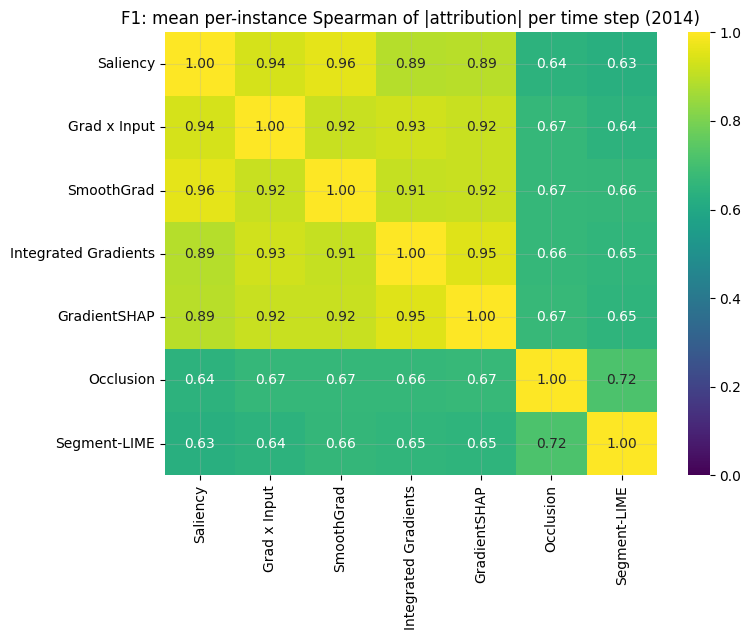

,Saliency,Grad x Input,SmoothGrad,Integrated Gradients,GradientSHAP,Occlusion,Segment-LIME
Saliency,1.00,0.94,0.96,0.89,0.89,0.64,0.63
Grad x Input,0.94,1.00,0.92,0.93,0.92,0.67,0.64
SmoothGrad,0.96,0.92,1.00,0.91,0.92,0.67,0.66
Integrated Gradients,0.89,0.93,0.91,1.00,0.95,0.66,0.65
GradientSHAP,0.89,0.92,0.92,0.95,1.00,0.67,0.65
Occlusion,0.64,0.67,0.67,0.66,0.67,1.00,0.72
Segment-LIME,0.63,0.64,0.66,0.65,0.65,0.72,1.00


mean agreement inside the gradient family = 0.92 (min 0.89) | gradient family vs Occlusion = 0.66 | gradient family vs Segment-LIME = 0.65 | Occlusion vs Segment-LIME = 0.72


In [30]:
from scipy.stats import rankdata

def mean_spearman(A, B):
    ra, rb = rankdata(A, axis=1), rankdata(B, axis=1)
    ra, rb = ra - ra.mean(1, keepdims=True), rb - rb.mean(1, keepdims=True)
    den = np.sqrt((ra ** 2).sum(1) * (rb ** 2).sum(1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.nanmean((ra * rb).sum(1) / den)

agree = pd.DataFrame([[mean_spearman(ATTR_ABS_T[a], ATTR_ABS_T[b]) for b in METHODS] for a in METHODS], index=METHODS, columns=METHODS)
plt.figure(figsize=(8, 6.5))
sns.heatmap(agree, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("F1: mean per-instance Spearman of |attribution| per time step (2014)"); plt.tight_layout(); plt.show()
display(agree.round(2))
grad_family = ["Saliency", "Grad x Input", "SmoothGrad", "Integrated Gradients", "GradientSHAP"]
inside = agree.loc[grad_family, grad_family].values[np.triu_indices(5, 1)]
print(f"mean agreement inside the gradient family = {inside.mean():.2f} (min {inside.min():.2f}) | gradient family vs Occlusion = {agree.loc[grad_family, 'Occlusion'].mean():.2f} | "
      f"gradient family vs Segment-LIME = {agree.loc[grad_family, 'Segment-LIME'].mean():.2f} | Occlusion vs Segment-LIME = {agree.loc['Occlusion', 'Segment-LIME']:.2f}")

**F1 — Your answer:**

The mean per-instance Spearman correlation between the absolute per-step attributions forms two clusters. The five gradient-based methods agree strongly with each other (mean 0.92, minimum 0.89; Saliency–SmoothGrad 0.96, IG–GradientSHAP 0.95, Saliency–Gradient×Input 0.94). Occlusion and segment-LIME form a second cluster (0.72 with each other) and agree much less with the gradient family (0.66 and 0.65 on average, lowest 0.63 for Saliency–Segment-LIME). The gradient methods are all based on local derivatives (IG and GradientSHAP average them along a path), so on a nearly smooth model they rank the steps alike. Occlusion and segment-LIME measure the finite effect of replacing a whole block (2 days) by the baseline, which captures non-linearity and interactions but also coarsens the time resolution.

### F2 (5 marks) — faithfulness
Implement a **deletion** test (Most Relevant First) on the PM2.5 channel *and* an **insertion** test (start from the baseline and add the most relevant steps first). Include a **random** ordering as a control. Report normalised AUCs for every method in one table.

Plot the memory profile (mean |attribution| per time step over 2014, per method). Unlike the temperature model in the lecture, which had a one-day memory, does your test now separate the methods? Explain why or why not.

,Deletion AUC (higher = better),Insertion AUC (higher = better),mean
Grad x Input,0.979,0.897,0.938
Integrated Gradients,0.976,0.891,0.933
GradientSHAP,0.977,0.886,0.931
Saliency,0.974,0.875,0.925
SmoothGrad,0.968,0.874,0.921
Occlusion,0.968,0.803,0.886
Segment-LIME,0.883,0.768,0.825
Random,0.597,0.405,0.501


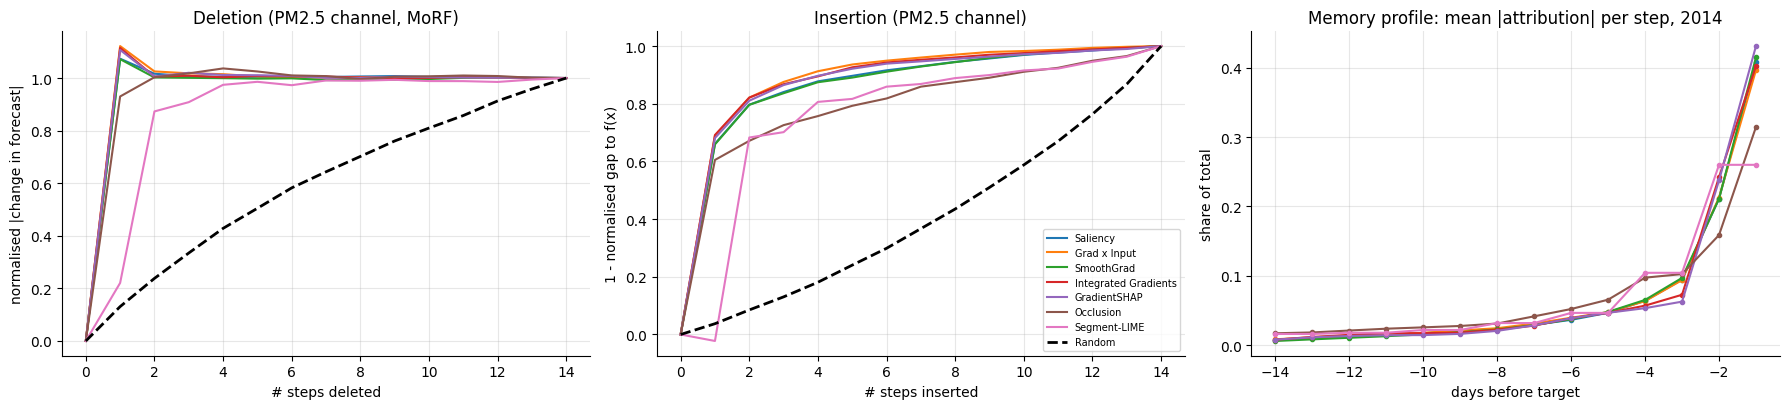

share of attribution on the last day (t-1) / last 3 days / last 7 days:


,t-1,last 3,last 7
Saliency,0.408,0.714,0.891
Grad x Input,0.396,0.703,0.886
SmoothGrad,0.415,0.723,0.903
Integrated Gradients,0.402,0.717,0.889
GradientSHAP,0.431,0.731,0.900
Occlusion,0.314,0.576,0.833
Segment-LIME,0.260,0.624,0.855


In [31]:
KS = list(range(0, W + 1))
PM = 0   # index of the PM2.5 channel

def _auc(c):
    return float(np.sum((c[1:] + c[:-1]) / 2 * np.diff(KS) / W))

def _replace_pm(x, replace_mask, baseline):
    xo = x.clone()
    xo[:, :, PM] = torch.where(torch.as_tensor(replace_mask), baseline[:, :, PM].expand(x.shape[0], -1), x[:, :, PM])
    return xo

def deletion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    """order[i] = time steps ranked most relevant first. Delete (-> baseline) the top-k steps of the PM2.5 channel;
    returns the mean |f(x) - f(x_k)| over instances."""
    rank = np.argsort(order, axis=1)
    with torch.no_grad():
        f0 = model(x)
        return np.array([(model(_replace_pm(x, rank < k, baseline)) - f0).abs().mean().item() for k in ks])

def insertion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    """start from the PM2.5 channel = baseline, put back the top-k steps; returns the mean |f(x) - f(x_k)|."""
    rank = np.argsort(order, axis=1)
    with torch.no_grad():
        f0 = model(x)
        return np.array([(model(_replace_pm(x, rank >= k, baseline)) - f0).abs().mean().item() for k in ks])

# attribution of each time step for the PM2.5 channel (gradient methods); Occlusion / Segment-LIME only have all-channel step scores
pm_scores = {m: (np.abs(ATTR[m][:, :, PM]) if m in ATTR else np.abs(ATTR_T[m])) for m in METHODS}
orders = {m: np.argsort(-s, axis=1) for m, s in pm_scores.items()}

rng = np.random.default_rng(SEED)
n_rand = 20
rand_del = np.mean([deletion_curve(np.argsort(rng.random((len(Xte_t), W)), axis=1), Xte_t) for _ in range(n_rand)], axis=0)
rand_ins = np.mean([insertion_curve(np.argsort(rng.random((len(Xte_t), W)), axis=1), Xte_t) for _ in range(n_rand)], axis=0)
del_c, ins_c = {m: deletion_curve(orders[m], Xte_t) for m in METHODS}, {m: insertion_curve(orders[m], Xte_t) for m in METHODS}
del_c["Random"], ins_c["Random"] = rand_del, rand_ins
end_del, start_ins = rand_del[-1], rand_ins[0]                  # identical for every ordering

rows = {m: {"Deletion AUC (higher = better)": _auc(del_c[m] / end_del),
            "Insertion AUC (higher = better)": 1 - _auc(ins_c[m] / start_ins)} for m in del_c}
faith = pd.DataFrame(rows).T
faith["mean"] = faith.mean(1)
display(faith.sort_values("mean", ascending=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for m in del_c:
    st = dict(color="k", ls="--", lw=2) if m == "Random" else {}
    axes[0].plot(KS, del_c[m] / end_del, label=m, **st); axes[1].plot(KS, 1 - ins_c[m] / start_ins, label=m, **st)
axes[0].set_title("Deletion (PM2.5 channel, MoRF)"); axes[0].set_xlabel("# steps deleted"); axes[0].set_ylabel("normalised |change in forecast|")
axes[1].set_title("Insertion (PM2.5 channel)"); axes[1].set_xlabel("# steps inserted"); axes[1].set_ylabel("1 - normalised gap to f(x)"); axes[1].legend(fontsize=7)
for m in METHODS:
    a = ATTR_ABS_T[m].mean(0); axes[2].plot(range(-W, 0), a / a.sum(), "o-", ms=3, label=m)
axes[2].set_title("Memory profile: mean |attribution| per step, 2014"); axes[2].set_xlabel("days before target"); axes[2].set_ylabel("share of total")
plt.tight_layout(); plt.show()
mem = pd.DataFrame({m: ATTR_ABS_T[m].mean(0) / ATTR_ABS_T[m].mean(0).sum() for m in METHODS}, index=[f"t-{W - k}" for k in range(W)]).T
print("share of attribution on the last day (t-1) / last 3 days / last 7 days:")
display(pd.DataFrame({"t-1": mem["t-1"], "last 3": mem[["t-1", "t-2", "t-3"]].sum(1), "last 7": mem[[f"t-{k}" for k in range(1, 8)]].sum(1)}).round(3))

**F2 — Your answer:**

Normalised deletion AUC (higher = faster change in forecast) is 0.979 for Gradient × Input, 0.977 GradientSHAP, 0.976 IG, 0.974 Saliency, 0.968 SmoothGrad, 0.968 Occlusion and 0.883 segment-LIME, against 0.597 for the random ordering; insertion scores (1 − gap AUC, higher = better) are 0.897, 0.886, 0.891, 0.875, 0.874, 0.803 and 0.768, against 0.405 for random. The memory profile is short: the gradient methods put 0.40–0.43 of their attribution on day t−1, 0.70–0.73 on the last 3 days and 0.83–0.90 on the last 7. The test now separates real methods from random ordering by a wide margin and isolates segment-LIME as the weakest (its 2-day segments give a coarse ranking), but it **does not separate the five gradient methods**: their deletion AUCs lie within 0.011 of each other, because they all rank the same dominant steps (t−1, t−2) first and, after those are deleted, little remains. The PM channel has a memory of about 3 days, so a 14-day deletion test is still dominated by the first one or two steps.

### F3 (2 marks) — channel-level faithfulness
Repeat the deletion test, but delete one whole **channel** at a time, ranked by each method's total channel attribution. Do the methods agree on whether wind or humidity matters more?

,Channel-deletion AUC (higher = better),Iws > DEWP on % of days
Saliency,0.808,99.178
Grad x Input,0.863,80.822
SmoothGrad,0.825,100.000
Integrated Gradients,0.903,86.027
GradientSHAP,0.941,75.342
Channel-occlusion,0.977,61.096
Random,0.714,NaN


share of total |attribution| per channel:


,log_pm,DEWP,PRES,Iws,doy_sin,doy_cos
Saliency,24.1,13.1,13.3,32.3,5.4,11.9
Grad x Input,25.5,15.1,13.9,24.6,7.2,13.8
SmoothGrad,24.6,12.9,14.0,31.0,5.7,11.8
Integrated Gradients,24.9,14.3,16.0,24.7,6.6,13.6
GradientSHAP,25.7,14.6,16.6,22.4,5.6,15.1
Channel-occlusion,27.4,14.7,12.5,18.6,6.4,20.4


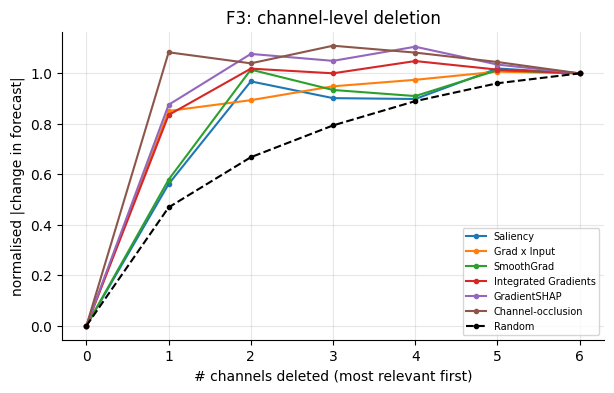

In [32]:
C = len(CHANNELS)

def _replace_channels(x, chan_mask, baseline):
    """chan_mask (n, C) True = replace the whole channel by the baseline"""
    m = torch.as_tensor(chan_mask)[:, None, :]
    return torch.where(m, baseline.expand_as(x), x)

def channel_deletion(order, x, baseline=BASELINE):
    rank = np.argsort(order, axis=1)
    with torch.no_grad():
        f0 = model(x)
        return np.array([(model(_replace_channels(x, rank < k, baseline)) - f0).abs().mean().item() for k in range(C + 1)])

# channel-level occlusion (replace one whole channel) as an extra, model-agnostic method
with torch.no_grad():
    f0 = model(Xte_t)
    chan_occ = np.stack([(f0 - model(_replace_channels(Xte_t, np.eye(C, dtype=bool)[c][None].repeat(len(Xte_t), 0), BASELINE))).numpy() for c in range(C)], axis=1)
chan_scores = {m: np.abs(a).sum(1) for m, a in ATTR.items()}                  # (n, C): total |attribution| of each channel
chan_scores["Channel-occlusion"] = np.abs(chan_occ)
rng = np.random.default_rng(SEED)
rand_ch = np.mean([channel_deletion(np.argsort(rng.random((len(Xte_t), C)), axis=1), Xte_t) for _ in range(20)], axis=0)
ch_curves = {m: channel_deletion(np.argsort(-s, axis=1), Xte_t) for m, s in chan_scores.items()}
ch_curves["Random"] = rand_ch

auc_c = lambda c: float(np.sum((c[1:] + c[:-1]) / 2 / C))
tab3 = pd.DataFrame({m: {"Channel-deletion AUC (higher = better)": auc_c(c / rand_ch[-1])} for m, c in ch_curves.items()}).T
share = pd.DataFrame({m: s.mean(0) / s.mean(0).sum() for m, s in chan_scores.items()}, index=CHANNELS).T
tab3["Iws > DEWP on % of days"] = [np.mean(chan_scores[m][:, 3] > chan_scores[m][:, 1]) * 100 if m in chan_scores else np.nan for m in tab3.index]
display(tab3.round(3)); print("share of total |attribution| per channel:"); display((share * 100).round(1))

fig, ax = plt.subplots(figsize=(7, 4))
for m, c in ch_curves.items():
    ax.plot(range(C + 1), c / rand_ch[-1], "o-", ms=3, label=m, **(dict(color="k", ls="--") if m == "Random" else {}))
ax.set_xlabel("# channels deleted (most relevant first)"); ax.set_ylabel("normalised |change in forecast|"); ax.legend(fontsize=7)
ax.set_title("F3: channel-level deletion"); plt.show()

**F3 — Your answer:**

Channel deletion AUC (higher = better) is 0.977 for channel-occlusion (which is the same operation as the test, so it is optimistic), 0.941 GradientSHAP, 0.903 IG, 0.863 Gradient × Input, 0.825 SmoothGrad and 0.808 Saliency, against 0.714 for random, so signed, baseline-aware methods rank channels better than the unsigned ones. The methods agree on the *direction* of the wind-versus-humidity question: wind speed (Iws) outranks the dew point (DEWP) on 99% (Saliency), 100% (SmoothGrad), 86% (IG), 81% (Gradient × Input), 75% (GradientSHAP) and 61% (channel-occlusion) of the days, and its average share of total attribution (18.6–32.3%) exceeds DEWP's (12.9–15.1%) for every method. They disagree on the magnitude: Saliency and SmoothGrad give wind a share of 31–32% and GradientSHAP 22%, and channel-occlusion puts the seasonal `doy_cos` channel (20.4%) above wind. The PM2.5 channel is first or second for every method (24–27%).

---
# Part G: Reflection (10 marks)
Answer in prose, 150–250 words each, citing your own results.

### G1 (4 marks)
You must explain tomorrow's pollution forecast to a city health officer with no ML training. Which single explanation from this assignment would you show them, and what would you say? Which explanation would you *not* show, and why?

**G1 — Your answer:**

I would show the health officer a **SHAP waterfall for tomorrow's forecast**, reduced to its four biggest bars and translated into plain factors. For the most polluted day (2014-10-11) I would say: "We expect about 210 µg/m³. We start from a typical day (about 72). Yesterday's heavy pollution (325) raises the forecast by about 74%, light wind yesterday adds 14% and no rain adds 9%. Pollution is expected to stay because the wind that could clear it away is weak." It has a baseline, signed contributions that sum exactly to the forecast (efficiency gap 1 × 10⁻¹⁴), the directions agree with atmospheric physics (C2), and the factors exp(φ) are easy to read once the log units are hidden.

I would *not* show the LIME output or the Integrated Gradients heatmaps. LIME's surrogate explains only about half the local variance (R² 0.53), under-predicts the forecast by 27–35%, rests on neighbours of which 99.3% are physically impossible (D2), and its tail features flip sign across seeds (D3). The IG time × channel heatmap depends on a baseline that mixes seasons, gives a large weight to calendar channels, and is hard to interpret. I would also warn the officer that the model missed turning points such as the 2014-01-16 smog build-up (forecast 128, actual 457.5) and the full clean-air drop on 2014-02-27, because it cannot see the weather of the day being forecast.

### G2 (3 marks)
Name the two design choices that changed your explanations the most (for example target transform, baseline, feature grouping, number of LIME samples). Give the evidence from your notebook.

**G2 — Your answer:**

The two choices that changed my explanations most were the **LIME sample count** and the **feature grouping**, with the oracle inputs a close third. LIME at 500 samples gives a mean coefficient of variation of 0.36 over the top-eight weights and sign flips in 18 of 26 features, against 0.13 and 17 flips at 5,000. `pm_lag_2` goes from CV 0.44 to 0.12, so a conclusion about the second-ranked history feature depends on the number of samples. Grouping changed the story for SHAP: feature by feature, `pm_lag_1` (0.211) is twice the next feature and the model looks like persistence, but at group level the weather groups sum to 49.0% against 45.7% for the PM2.5 history (C5). Grouping did not help LIME–SHAP agreement (0.703 feature-level vs 0.665 group-level, D4). A third choice, the oracle inputs, moved the persistence share from 45.7% to 24.5% and cut the wind-direction group by 65% (C6), showing how importance depends on which correlated features the model can use. Finally the log target fixed the units: SHAP values are in log1p units and the base value is 71.6 µg/m³, not 97.0.

### G3 (3 marks)
Propose an explanation-based **drift alarm** for this model in production. State exactly what you would compute each week and the threshold you would use, then test it by comparing 2013 with 2014.

threshold = mean + 3 sd of 2013 weekly distances = 0.113 + 3 x 0.039 = 0.231
2013: 0 of 52 weeks above threshold, 0 alarms (2 consecutive weeks)
2014: 0 of 52 weeks above threshold, 0 alarms (2 consecutive weeks)
mean weekly distance: 2013 = 0.113, 2014 = 0.112


,2013 share,2014 share,change (pp)
PM recent lags (1-3),0.356,0.381,2.521
PM older lags (4-7),0.031,0.032,0.160
PM rolling stats,0.041,0.043,0.226
Weather yesterday,0.261,0.236,-2.520
Weather change,0.089,0.087,-0.233
Wind direction,0.169,0.166,-0.236
Calendar,0.052,0.053,0.080


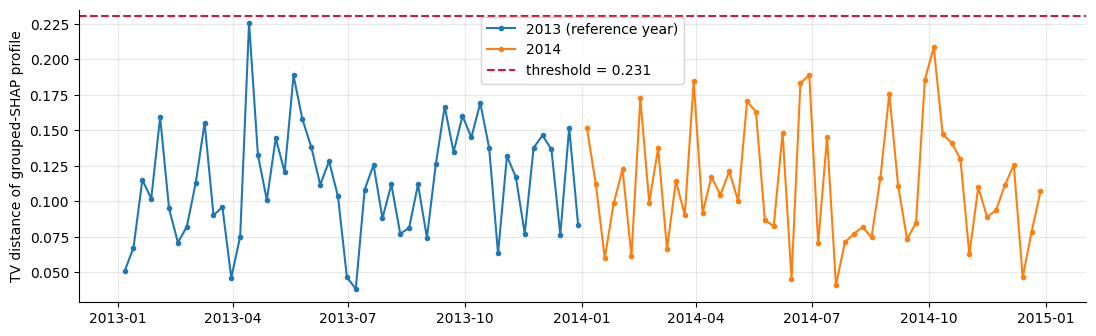

weekly MAE (µg/m³): 2013 mean = 46.1, 2014 mean = 45.2



[first attempt: |SHAP| shares] simulated fault from 2014-07-01: 0 of 52 weeks above threshold; mean distance before / after the fault: 0.118 / 0.121  -> the alarm is blind to it
MAE (µg/m³) with the faulty input: 46.1 (clean: 45.1)
monitored features: ['pm_lag_1', 'Iws_lag_1', 'wind_NW', 'Ir_lag_1', 'DEWP_diff_1', 'PRES_lag_1', 'wind_SE', 'pm_lag_2']
CUSUM (k = 1 sd, alarm threshold H = 7 sd) | max over weeks and features: 2013 = 6.6, 2014 = 2.9, 2014 with sensor fault = 13.9
2014 actual per feature : {'pm_lag_1': 1.8, 'Iws_lag_1': 1.2, 'wind_NW': 1.9, 'Ir_lag_1': 2.9, 'DEWP_diff_1': 1.8, 'PRES_lag_1': 0.7, 'wind_SE': 2.5, 'pm_lag_2': 2.0}
2014 with fault         : {'pm_lag_1': 1.8, 'Iws_lag_1': 13.9, 'wind_NW': 1.1, 'Ir_lag_1': 2.8, 'DEWP_diff_1': 1.7, 'PRES_lag_1': 0.7, 'wind_SE': 1.5, 'pm_lag_2': 2.0}
first alarm with the fault: 2014-11-16 (fault starts 2014-07-01) | feature: Iws_lag_1
alarms on the real 2014 data: 0 weeks | on 2013 itself: 0 weeks


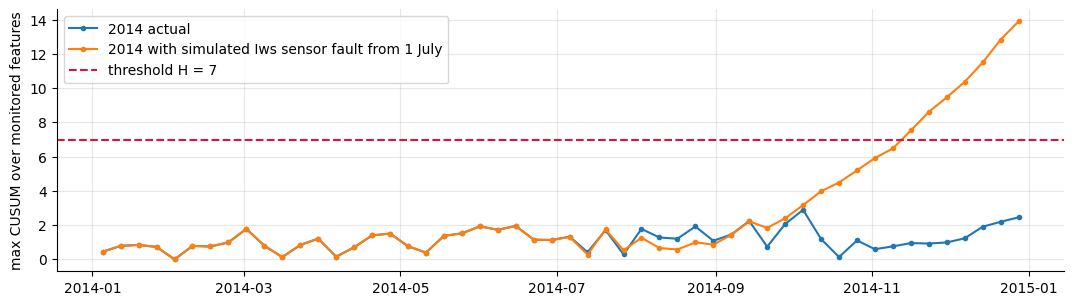

PRES +15 hPa from July: MAE 45.2 (clean 45.1); max CUSUM 3.0


In [33]:
# Drift statistic: weekly share of each feature group in the (grouped) SHAP importance, compared with a reference year.
sv_val = tree_explainer.shap_values(X_val)
gs_val = grouped(sv_val, feature_names, FEATURE_GROUPS); gs_val.index = X_val.index
gs_test = group_shap.copy()

def weekly_shares(g):
    w = g.abs().resample("W").mean()
    w = w[g.abs().resample("W").count().iloc[:, 0] >= 5]          # ignore partial weeks
    return w.div(w.sum(1), axis=0)

ref = gs_val.abs().mean(); ref = ref / ref.sum()                     # 2013 reference profile
def tv(shares):                                                     # total-variation distance to the reference
    return 0.5 * (shares - ref).abs().sum(1)

s13, s14 = weekly_shares(gs_val), weekly_shares(gs_test)
d13, d14 = tv(s13), tv(s14)
THR = d13.mean() + 3 * d13.std()
alarm = lambda d: (d > THR) & (d.shift(1) > THR)                      # two consecutive weeks above threshold
flag13, flag14 = d13 > THR, d14 > THR
print(f"threshold = mean + 3 sd of 2013 weekly distances = {d13.mean():.3f} + 3 x {d13.std():.3f} = {THR:.3f}")
print(f"2013: {flag13.sum()} of {len(d13)} weeks above threshold, {alarm(d13).sum()} alarms (2 consecutive weeks)")
print(f"2014: {flag14.sum()} of {len(d14)} weeks above threshold, {alarm(d14).sum()} alarms (2 consecutive weeks)")
print("mean weekly distance: 2013 = %.3f, 2014 = %.3f" % (d13.mean(), d14.mean()))
ref14 = gs_test.abs().mean(); ref14 = ref14 / ref14.sum()
display(pd.DataFrame({"2013 share": ref, "2014 share": ref14, "change (pp)": (ref14 - ref) * 100}).round(3))

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(d13.index, d13.values, "o-", ms=3, label="2013 (reference year)"); ax.plot(d14.index, d14.values, "o-", ms=3, label="2014")
ax.axhline(THR, color="crimson", ls="--", label=f"threshold = {THR:.3f}"); ax.set_ylabel("TV distance of grouped-SHAP profile"); ax.legend(); plt.show()
# also: the same alarm on the forecast error, for comparison
mae_w = lambda y, p: pd.Series(np.abs(y.values - p), index=y.index).resample("W").mean()
print("weekly MAE (µg/m³): 2013 mean = %.1f, 2014 mean = %.1f" % (mae_w(to_ug(y_val), to_ug(lgbm.predict(X_val))).mean(), mae_w(y_test_ug, pred_lgbm_ug).mean()))

# --- does the alarm actually fire? simulate a broken wind-speed sensor in 2014 (Iws_lag_1 stuck at 0 from 1 July)
X_fault = X_test.copy(); X_fault.loc["2014-07-01":, "Iws_lag_1"] = 0.0
gs_f = grouped(tree_explainer.shap_values(X_fault), feature_names, FEATURE_GROUPS); gs_f.index = X_fault.index
d_f = tv(weekly_shares(gs_f))
print(f"\n[first attempt: |SHAP| shares] simulated fault from 2014-07-01: {(d_f > THR).sum()} of {len(d_f)} weeks above threshold; "
      f"mean distance before / after the fault: {d_f[:'2014-06-30'].mean():.3f} / {d_f['2014-07-01':].mean():.3f}  -> the alarm is blind to it")
print("MAE (µg/m³) with the faulty input: %.1f (clean: %.1f)" % (mean_absolute_error(y_test_ug, to_ug(lgbm.predict(X_fault))), mean_absolute_error(y_test_ug, pred_lgbm_ug)))

# --- final alarm: CUSUM on the weekly mean (signed) SHAP value of each monitored feature.
# A broken input changes the DIRECTION of its push; weekly noise is large, so we accumulate small persistent shifts (CUSUM).
CALENDAR = set(FEATURE_GROUPS["Calendar"])
monitored = [f for f in pd.Series(np.abs(sv_val).mean(0), index=feature_names).sort_values(ascending=False).index if f not in CALENDAR][:8]
def weekly_feat(sv, idx):
    d = pd.DataFrame(sv, index=idx, columns=feature_names)[monitored]
    w = d.resample("W").mean()
    return w[d.resample("W").count().iloc[:, 0] >= 5]
wf13, wf14 = weekly_feat(sv_val, X_val.index), weekly_feat(shap_exp.values, X_test.index)
wf_f = weekly_feat(tree_explainer.shap_values(X_fault), X_fault.index)
mu13, sd13 = wf13.mean(), wf13.std()
K, H = 1.0, 7.0          # slack of 1 sd; alarm when the cumulative sum exceeds 7 sd (just above the 2013 maximum)
def cusum(w):
    z = ((w - mu13) / sd13).values; s_hi = s_lo = np.zeros(z.shape[1]); out = []
    for row in z:
        s_hi, s_lo = np.maximum(0, s_hi + row - K), np.maximum(0, s_lo - row - K); out.append(np.maximum(s_hi, s_lo))
    return pd.DataFrame(out, index=w.index, columns=w.columns)
c13, c14, cf = cusum(wf13), cusum(wf14), cusum(wf_f)
print(f"monitored features: {monitored}")
print(f"CUSUM (k = {K:.0f} sd, alarm threshold H = {H:.0f} sd) | max over weeks and features: 2013 = {c13.max().max():.1f}, 2014 = {c14.max().max():.1f}, 2014 with sensor fault = {cf.max().max():.1f}")
print("2014 actual per feature :", c14.max().round(1).to_dict())
print("2014 with fault         :", cf.max().round(1).to_dict())
hit = (cf > H).any(axis=1)
print("first alarm with the fault:", hit[hit].index[0].date() if hit.any() else "none", "(fault starts 2014-07-01) | feature:", cf.loc[hit[hit].index[0]].idxmax() if hit.any() else "-")
print("alarms on the real 2014 data:", int((c14 > H).any(axis=1).sum()), "weeks | on 2013 itself:", int((c13 > H).any(axis=1).sum()), "weeks")
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(c14.max(axis=1), "o-", ms=3, label="2014 actual"); ax.plot(cf.max(axis=1), "o-", ms=3, label="2014 with simulated Iws sensor fault from 1 July")
ax.axhline(H, color="crimson", ls="--", label=f"threshold H = {H:.0f}"); ax.set_ylabel("max CUSUM over monitored features"); ax.legend(); plt.show()
# a fault in an input the model barely uses is invisible to this alarm, and also harmless for accuracy:
Xp = X_test.copy(); Xp.loc["2014-07-01":, "PRES_lag_1"] += 15
print("PRES +15 hPa from July: MAE %.1f (clean %.1f); max CUSUM %.1f" % (mean_absolute_error(y_test_ug, to_ug(lgbm.predict(Xp))), mean_absolute_error(y_test_ug, pred_lgbm_ug),
      cusum(weekly_feat(tree_explainer.shap_values(Xp), Xp.index)).max().max()))


**G3 — Your answer:**

**Alarm.** Each week I compute the mean *signed* SHAP value of each monitored input (the eight most important non-calendar features: `pm_lag_1`, `Iws_lag_1`, `wind_NW`, `Ir_lag_1`, `DEWP_diff_1`, `PRES_lag_1`, `wind_SE`, `pm_lag_2`), standardise it with the mean and standard deviation of that feature's weekly means in the reference year 2013, and update a two-sided CUSUM with slack k = 1 sd; the alarm fires when any CUSUM exceeds **H = 7 sd**. My first idea, the total-variation distance between weekly *grouped |SHAP| shares* (threshold mean + 3 sd = 0.231), was blind: it gave 0 alarms for both years and also missed a simulated broken wind sensor, because a stuck input changes the *sign* of its contribution, not its size.

**2013 vs 2014.** The grouped share profile hardly moves (mean weekly distance 0.113 vs 0.112; recent lags 35.6% → 38.1%, weather yesterday 26.1% → 23.6%), the CUSUM maximum is 6.6 in 2013 and 2.9 in 2014, there are no alarms, and the weekly MAE is stable (46.1 vs 45.2 µg/m³): no drift. **Check that it can fire:** with `Iws_lag_1` stuck at 0 from 1 July 2014 the CUSUM reaches 13.9, with the first alarm on 2014-11-16 (about 20 weeks late). A +15 hPa pressure offset is not detected (CUSUM 3.0), but it is also harmless (MAE 45.2 vs 45.1), since the model barely uses pressure. The alarm guards the inputs the model relies on, and a simple input-range check should run next to it for faster detection.

---
# Bonus (up to 10 marks): pick up to two

- **Multi-horizon (5).** Forecast PM2.5 at t+1, t+3 and t+7 with three LightGBMs. Show how grouped SHAP shifts from lags to calendar and weather as the horizon grows.
- **TimeSHAP-style pruning (5).** For the sequence model, group all time steps older than *k* days into one "past" coalition and compute KernelSHAP on the reduced input. Find the smallest *k* that keeps 90% of the attribution.
- **Counterfactual (5).** For the most polluted test day, find the smallest change in yesterday's wind speed and direction that brings the forecast below 75 µg/m³ (China's 24-hour PM2.5 standard). Is the counterfactual physically plausible?

**Bonuses completed:** Multi-horizon (Bonus 1) and Counterfactual (Bonus 3). The two code cells and their answers are below.

,LightGBM MAE,persistence MAE,train-median MAE,early-stop trees,trees used
1,45.28,52.75,56.56,317.0,317.0
3,57.55,82.43,56.56,3.0,200.0
7,57.59,78.35,56.56,1.0,200.0


,t+1,t+3,t+7
PM recent lags (1-3),33.0,9.6,5.0
PM older lags (4-7),2.6,9.7,16.5
PM rolling stats,4.5,16.3,25.0
Weather yesterday,25.1,25.4,17.4
Weather change,10.5,9.1,9.3
Wind direction,19.1,1.0,1.2
Calendar,5.2,28.9,25.7


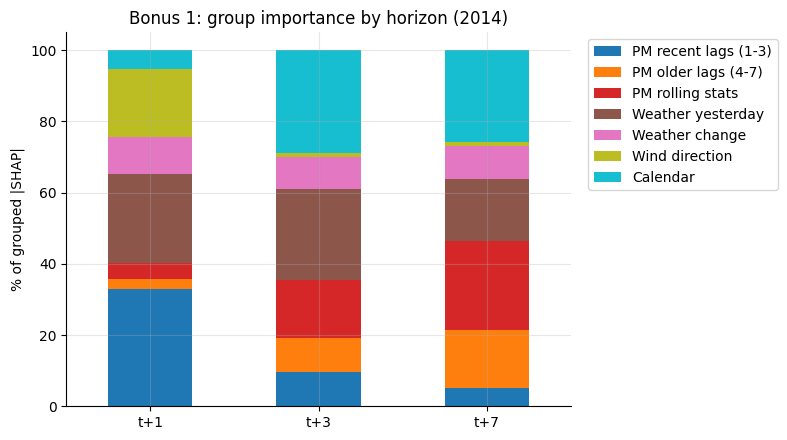

In [34]:
# Bonus 1 - multi-horizon forecasts: origin = end of day t-1, target = PM2.5 on day (t-1+h)
def horizon_data(h):
    Xh = data[feature_names].copy()
    tdates = Xh.index + pd.Timedelta(days=h - 1)
    d = tdates.dayofyear
    Xh["doy_sin"], Xh["doy_cos"] = np.sin(2 * np.pi * d / 365.25), np.cos(2 * np.pi * d / 365.25)    # calendar of the TARGET day
    md = tdates.month * 100 + tdates.day
    Xh["is_heating_season"] = ((md >= 1115) | (md <= 315)).astype(float); Xh["dow"] = tdates.dayofweek.astype(float)
    yh = (np.log1p(daily_clean["pm2.5"]) if USE_LOG_TARGET else daily_clean["pm2.5"]).reindex(tdates).values
    ok = ~np.isnan(yh)
    return Xh[ok], pd.Series(yh[ok], index=Xh.index[ok]), tdates[ok]

H_PARAMS = {**LGB_PARAMS, "num_leaves": 4, "min_child_samples": 50, "reg_lambda": 10, "colsample_bytree": 0.5}   # small trees: the long-horizon signal is weak
H_RES, H_GROUP = {}, {}
for h in (1, 3, 7):
    Xh, yh, td = horizon_data(h)
    tr, va, te = td <= "2012-12-31", td.year == 2013, td.year == 2014
    es = lgb.LGBMRegressor(**H_PARAMS).fit(Xh[tr], yh[tr], eval_set=[(Xh[va], yh[va])], callbacks=[lgb.early_stopping(100, verbose=False)])
    n_trees = max(es.best_iteration_, 200)        # for h >= 3 early stopping on 2013 picks ~1 tree (no skill); keep >= 200 trees so SHAP has something to explain
    mh = lgb.LGBMRegressor(**{**H_PARAMS, "n_estimators": n_trees}).fit(Xh[tr], yh[tr])
    ph = to_ug(mh.predict(Xh[te])); persist = Xh[te]["pm_lag_1"].values
    H_RES[h] = {"LightGBM MAE": mean_absolute_error(to_ug(yh[te]), ph), "persistence MAE": mean_absolute_error(to_ug(yh[te]), persist),
                "train-median MAE": mean_absolute_error(to_ug(yh[te]), np.full(te.sum(), np.median(to_ug(yh[tr])))),
                "early-stop trees": es.best_iteration_, "trees used": n_trees}
    sv_h = shap.TreeExplainer(mh).shap_values(Xh[te])
    g = grouped(sv_h, feature_names, FEATURE_GROUPS).abs().mean(); H_GROUP[f"t+{h}"] = g / g.sum() * 100
display(pd.DataFrame(H_RES).T.round(2))
hg = pd.DataFrame(H_GROUP)
display(hg.round(1))
hg.T.plot.bar(stacked=True, figsize=(8, 4.5), colormap="tab10", rot=0); plt.ylabel("% of grouped |SHAP|"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.title("Bonus 1: group importance by horizon (2014)"); plt.tight_layout(); plt.show()

In [35]:
# Bonus 3 - counterfactual for the most polluted test day: change yesterday's wind speed and direction only
TARGET_UG = 75
x_cf = X_test.iloc[idx_high].copy()
print(f"{X_test.index[idx_high].date()}: forecast {pred_lgbm_ug[idx_high]:.1f} µg/m³ (actual {y_test_ug.values[idx_high]:.1f}), yesterday {x_cf['pm_lag_1']:.0f} µg/m³, "
      f"Iws_lag_1 = {x_cf['Iws_lag_1']:.1f} m/s, wind = {[w for w in WINDS if x_cf[f'wind_{w}'] == 1]}")
iws_grid = np.linspace(0, X_train["Iws_lag_1"].max(), 400)
iws_sd = X_train["Iws_lag_1"].std()
rows = []
for w in WINDS:
    G = np.tile(x_cf.values.astype(float), (len(iws_grid), 1))
    G[:, feature_names.index("Iws_lag_1")] = iws_grid
    for ww in WINDS:
        G[:, feature_names.index(f"wind_{ww}")] = float(ww == w)
    pr = to_ug(lgbm.predict(pd.DataFrame(G, columns=feature_names)))
    changed = x_cf[f"wind_{w}"] != 1
    cost = np.abs(iws_grid - x_cf["Iws_lag_1"]) / iws_sd + 1.0 * changed          # a wind-direction change costs as much as 1 sd of wind speed
    for k in range(len(iws_grid)):
        rows.append((w, iws_grid[k], pr[k], cost[k]))
cf = pd.DataFrame(rows, columns=["wind", "Iws_lag_1", "forecast", "cost"])
feasible = cf[cf["forecast"] < TARGET_UG]
print(f"lowest forecast reachable by changing only wind speed/direction: {cf['forecast'].min():.1f} µg/m³ "
      f"(wind={cf.loc[cf['forecast'].idxmin(), 'wind']}, Iws_lag_1={cf.loc[cf['forecast'].idxmin(), 'Iws_lag_1']:.0f})")
if len(feasible):
    best = feasible.loc[feasible["cost"].idxmin()]
    print("smallest change reaching < 75:", best.round(1).to_dict())
else:
    print(f"no wind speed/direction combination brings the forecast below {TARGET_UG} µg/m³")
piv = cf.pivot_table(index=pd.cut(cf["Iws_lag_1"], 8), columns="wind", values="forecast", observed=True)
display(piv.round(0))
print(f"for scale: training Iws_lag_1 median = {X_train['Iws_lag_1'].median():.1f}, 95th pct = {X_train['Iws_lag_1'].quantile(.95):.0f}, max = {X_train['Iws_lag_1'].max():.0f} m/s")
# what would it take? let yesterday's PM2.5 (the dominant input) fall as well, with a strong NW wind
G = np.tile(x_cf.values.astype(float), (200, 1)); pm_grid = np.linspace(10, x_cf["pm_lag_1"], 200)
G[:, feature_names.index("pm_lag_1")] = pm_grid
G[:, feature_names.index("Iws_lag_1")] = 146
for ww in WINDS:
    G[:, feature_names.index(f"wind_{ww}")] = float(ww == "NW")
pr = to_ug(lgbm.predict(pd.DataFrame(G, columns=feature_names)))
print(f"\nwith strong NW wind (146 m/s) AND a lower pm_lag_1: forecast < 75 only if pm_lag_1 <= {pm_grid[pr < TARGET_UG].max() if (pr < TARGET_UG).any() else float('nan'):.0f} µg/m³ (actual yesterday: {x_cf['pm_lag_1']:.0f})")
for w in WINDS:
    print(f"  forecast with wind={w} and yesterday's Iws unchanged:{cf[(cf.wind == w)].iloc[(cf[(cf.wind == w)]['Iws_lag_1'] - x_cf['Iws_lag_1']).abs().argsort()[:1]]['forecast'].values[0]:.0f}")

2014-10-11: forecast 210.6 µg/m³ (actual 197.6), yesterday 325 µg/m³, Iws_lag_1 = 11.6 m/s, wind = ['SE']
lowest forecast reachable by changing only wind speed/direction: 102.8 µg/m³ (wind=NW, Iws_lag_1=63)
no wind speed/direction combination brings the forecast below 75 µg/m³


wind,NE,NW,SE,cv
Iws_lag_1,,,,
"(-0.586, 73.2]",177.0,153.0,185.0,180.0
"(73.2, 146.4]",123.0,104.0,133.0,125.0
"(146.4, 219.6]",125.0,108.0,134.0,127.0
"(219.6, 292.8]",126.0,111.0,135.0,129.0
"(292.8, 366.0]",127.0,113.0,135.0,130.0
"(366.0, 439.2]",127.0,113.0,135.0,130.0
"(439.2, 512.4]",127.0,113.0,135.0,130.0
"(512.4, 585.6]",127.0,113.0,135.0,130.0


for scale: training Iws_lag_1 median = 38.0, 95th pct = 214, max = 586 m/s

with strong NW wind (146 m/s) AND a lower pm_lag_1: forecast < 75 only if pm_lag_1 <= 175 µg/m³ (actual yesterday: 325)
  forecast with wind=NW and yesterday's Iws unchanged:189
  forecast with wind=NE and yesterday's Iws unchanged:206
  forecast with wind=SE and yesterday's Iws unchanged:211
  forecast with wind=cv and yesterday's Iws unchanged:210


**Bonus 1 — Your answer (multi-horizon):**

For forecast horizons of 1, 3 and 7 days, the LightGBM test MAE is 45.28, 57.55 and 57.59 µg/m³, against 52.75, 82.43 and 78.35 for persistence and 56.56 for a constant training median. The 1-day model beats the constant clearly, but beyond that the model has **no skill over a constant** (early stopping on 2013 picked only 3 and 1 trees, so I used 200 small trees only to have something to explain). Grouped SHAP shares move as expected: recent PM2.5 lags fall from 33.0% to 9.6% and 5.0%, and wind direction from 19.1% to 1.0% and 1.2%, while the calendar rises from 5.2% to 28.9% and 25.7% and rolling statistics from 4.5% to 16.3% and 25.0% (older lags 2.6% → 9.7% → 16.5%). The shift from lags and wind to calendar and slow statistics is what physics suggests, but with no skill beyond the median these long-horizon attributions describe memorised patterns, not reliable drivers.

**Bonus 3 — Your answer (counterfactual):**

For the most polluted test day (2014-10-11: forecast 210.6, actual 197.6 µg/m³, yesterday 325 µg/m³, SE wind, `Iws_lag_1` = 11.6 m/s), **no change of yesterday's wind speed and direction brings the forecast below 75 µg/m³**. The lowest reachable forecast is 102.8 µg/m³ (NW wind, `Iws_lag_1` ≈ 63 m/s), and it stays between 104 and 113 for stronger winds. The forecast drops below 75 only if yesterday's PM2.5 is also lowered to ≤ 175 µg/m³ with a 146 m/s NW wind. A counterfactual that changes wind alone is physically implausible: yesterday's wind would have changed yesterday's PM2.5 too, and the model reads `pm_lag_1` as the dominant input, so a causally consistent counterfactual needs a different yesterday as a whole, not just a different wind.